# FabricSort: ระบบจำแนกเศษผ้าเพื่อนำไปรีไซเคิล

**Applied Machine Learning** · จำแนกรูปเศษผ้า 1 รูปเป็น **Cotton / Polyester / Silk / Viscose** พร้อมค่าความมั่นใจ

Notebook นี้ทำงานครบในการกด **Run All** ครั้งเดียว โดยแก้เฉพาะ cell **Config (ส่วนที่ 0)**

**Flow ของเวอร์ชันนี้**
1. เทรน CNN 4 ตัว (ResNet50, DenseNet121, EfficientNet-B0, ConvNeXt-Tiny) ตัวละ **3 รอบ** ตามสไลด์ของวิชา:
   รอบ 1 ไม่ทำ augmentation, รอบ 2 แบบเบา (v1), รอบ 3 แบบหนัก (v2) และรอบ 4 แบบรักษาพื้นผิวผ้า (texture) รวม 16 run
2. เลือก **Top 1 (โมเดล + รอบ)** จาก Val Macro-F1
3. วัดผล **ก่อนจูน** (สูตร default, 3 seed) → จูน hyperparameter ด้วย **Optuna** → วัดผล **หลังจูน** (3 seed)
4. ประเมินบน Test ครั้งเดียว แล้ววัดผลกับ **Unseen data** (รูปผ้าจากอินเทอร์เน็ต) พร้อมกราฟ Train vs Val vs Test vs Unseen
5. export โมเดล และสร้างแอป Streamlit (กราฟใน notebook ใช้ matplotlib ส่วนในแอปใช้ plotly)

> **ทำไมไม่ใช้ Keras:** เริ่มจาก Keras Applications ก่อนตามแผน แต่ Keras 3 (backend PyTorch) บน RTX 4050 ใช้ไม่ได้จริง:
> batch 32 ใช้หน่วยความจำเกิน 6 GB, batch 16 หน่วยความจำรั่วทุก step และช้ามาก (EfficientNetB0 417 วินาที/epoch,
> ConvNeXtTiny 523 วินาที/epoch เทียบกับ PyTorch ~40–50 วินาที/epoch) ส่วน TensorFlow ใช้ GPU บน Windows ไม่ได้
> จึงใช้สถาปัตยกรรมเดียวกันจาก **torchvision** แทน (ResNet50V2 ของ Keras → ResNet50 ของ torchvision)

| ส่วน | เนื้อหา | ผลลัพธ์ |
|---|---|---|
| – | ติดตั้งไลบรารี | แพ็กเกจตาม `requirements.txt` |
| 0 | Config | ตั้งค่าจุดเดียว |
| 1 | Setup + โมดูลที่ใช้ร่วมกับแอป | `fabric_lib.py` |
| 2–3 | Load + EDA, Clean + Split (เหมือนเวอร์ชันก่อน) | `results/manifest.csv`, `results/split.csv` |
| 4 | ฟังก์ชันเทรนและวัดผลร่วม | – |
| 5 | 4 โมเดล × 4 รอบ (none / v1 / v2 / texture) | `results/screening.csv` |
| 6 | เลือก Top 1 | `results/selection.json` |
| 7 | ก่อนจูน (3 seed) | `results/runs.csv` |
| 8 | จูนด้วย Optuna | `results/optuna_trials.csv` |
| 9 | หลังจูน (3 seed) | `results/runs.csv` |
| 10 | Test: ก่อน vs หลัง + Test ของทั้ง 16 run | `results/test_before_after.csv`, `screening_test.csv` ฯลฯ |
| 10b | Generalization (ตามสไลด์) | `results/generalization.csv`, `gen_*.png` |
| 10c | Unseen data | `results/unseen_metrics.csv`, `unseen_predictions.csv` |
| 11 | Error analysis | รูปที่ทายผิด |
| 12 | Export | `models/best_model.pth` + `model_meta.json` |
| 13–14 | เขียนและเปิดแอป | `app.py`, http://localhost:8501 |

**งานวิจัยอ้างอิง**
- **[R1]** Zhu et al. (2023). *Identification of cashmere and wool based on LBP and GLCM texture feature selection.* → baseline SVM (เวอร์ชันแรก)
- **[R2]** Mudaffarsyah et al. (2024). *Klasifikasi Jenis Lamun Menggunakan Ekstraksi Fitur GLCM dan Algoritma KNN.* → baseline KNN (เวอร์ชันแรก)
- **[R3]** Enow Gnoupa et al. (2025). *Multimodal Feature Inputs Enable Improved Automated Textile Identification.* Textiles 5(3). → ResNet50 ดีที่สุดเมื่อเทียบกับ InceptionV3, DenseNet และ VGG-19

เวอร์ชันก่อนหน้า (SVM/KNN และ ResNet50/ConvNeXt V2/DINOv2) ถูกลบออกแล้ว เหลือเฉพาะงานปัจจุบัน

## ติดตั้งไลบรารี

ตรวจว่าขาดแพ็กเกจอะไร ถ้าครบแล้วจะข้ามทันที เครื่องที่มี GPU NVIDIA จะได้ PyTorch แบบ CUDA ตาม `requirements.txt`
แนะนำให้ใช้ virtual environment ของโปรเจค (ดู README.md)

In [1]:
# ===== ติดตั้งไลบรารี: ครั้งแรกจะติดตั้ง ครั้งต่อไปจะข้ามเองถ้าครบแล้ว =====
import importlib, importlib.util, subprocess, sys
from pathlib import Path

assert sys.version_info >= (3, 11), f"ต้องใช้ Python 3.11 ขึ้นไป (ตอนนี้ {sys.version.split()[0]})"
REQUIRED = {"torch": "torch", "torchvision": "torchvision", "numpy": "numpy", "pandas": "pandas",
            "sklearn": "scikit-learn", "scipy": "scipy", "optuna": "optuna", "plotly": "plotly",
            "PIL": "pillow", "joblib": "joblib", "tqdm": "tqdm", "matplotlib": "matplotlib",
            "streamlit": "streamlit"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    if not Path("requirements.txt").exists():
        raise FileNotFoundError("ไม่พบ requirements.txt ให้เปิด notebook จากโฟลเดอร์โปรเจค")
    print("ยังไม่มีแพ็กเกจ:", ", ".join(missing), "-> ติดตั้งตาม requirements.txt")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "-r", "requirements.txt"])
    importlib.invalidate_caches()
    if any(m in sys.modules for m in ("torch", "numpy")):
        raise SystemExit("ติดตั้งเสร็จแล้ว: ให้ Restart kernel แล้ว Run All อีกครั้ง")
check = subprocess.run([sys.executable, "-c", "import numpy, sklearn.metrics, scipy.stats, torch, torchvision, optuna"],
                       capture_output=True, text=True)
if check.returncode != 0:
    err = check.stderr.strip().splitlines()[-1] if check.stderr.strip() else "unknown error"
    hint = ("\nWindows Smart App Control บล็อกไฟล์ DLL ของไลบรารี ดูหัวข้อ 'ปัญหา Smart App Control' ใน README.md"
            if "Application Control" in err or "WinError 4551" in err else "")
    raise ImportError(f"import ไลบรารีไม่สำเร็จด้วย {sys.executable}:\n{err}{hint}")
print(f"ไลบรารีครบแล้ว (Python {sys.version.split()[0]})")

ไลบรารีครบแล้ว (Python 3.14.2)


## 0. Config

ค่าที่ปรับได้ทั้งหมดอยู่ใน cell นี้ที่เดียว

**โครงสร้างโฟลเดอร์ข้อมูล**
```
dataset/
  iBUG/{Cotton,Polyester,Silk,Viscose}/<ID ชิ้นผ้า>/im_1..im_4.png
  TextileClass7/{Cotton,Polyester,Silk,Viscose}/*.jpg
```

**`SMOKE = True`** ใช้ทดสอบว่า notebook รันครบทุก cell ได้ในไม่กี่นาที (2 epoch, 2 trial, ข้อมูลส่วนน้อย)
ผลลัพธ์จะเขียนแยกไว้ที่ `results/_smoke/` และ `models/_smoke/` ไม่ทับผลจริง

In [2]:
# ===== Config: แก้เฉพาะ cell นี้ =====
from pathlib import Path

PROJECT_DIR = Path.cwd()                 # โฟลเดอร์ที่มี notebook นี้ (ให้เปิด notebook จากโฟลเดอร์โปรเจค)
DATA_DIR    = PROJECT_DIR / "dataset"    # dataset/<source>/<Class>/...
OUTPUT_DIR  = PROJECT_DIR                # ที่เก็บผลลัพธ์ทั้งหมด

SOURCES = ["iBUG", "TextileClass7"]
# TextileClass7: Roboflow ทำ augmentation ไว้ 3 เวอร์ชันต่อรูป ชื่อไฟล์เป็น "<ต้นฉบับ>_jpg.rf.<hash>.jpg"
# จึงตัด "_jpg.rf.<hash>" ออกเพื่อให้ทุกเวอร์ชันของรูปเดียวกันเป็นชิ้นผ้าเดียวกัน
GROUP_REGEX = {"iBUG": None, "TextileClass7": r"_(jpe?g|png)\.rf\.[0-9a-f]+$"}
FABRIC_GROUPS_CSV = PROJECT_DIR / "data_audit" / "fabric_groups.csv"  # รูปหลายรูปของผ้าชิ้นเดียวกัน
EXCLUDE_CSV       = PROJECT_DIR / "data_audit" / "exclude.csv"        # รูปที่ label ขัดแย้ง
EVAL_ONE_PER_PIECE = True                # Val/Test ใช้ 1 รูปต่อชิ้นผ้า

SEED     = 42
IMG_SIZE = 224
MIN_SIDE = 64
SPLIT    = (0.70, 0.15, 0.15)            # Train / Val / Test
N_JOBS   = -1                            # จำนวน process ตอนสแกนรูป

# ===== โมเดลและการเทรน =====
MODEL_KEYS  = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny"]   # torchvision
ROUNDS = ["none", "v1", "v2", "texture"] # รอบตามสไลด์ (none/v1/v2) + texture = augmentation ที่รักษาพื้นผิวผ้า
UNSEEN_DIR = PROJECT_DIR / "unseen_data" # รูปจากอินเทอร์เน็ต (TextileNet) ใช้วัดผลอย่างเดียว
SEEDS       = (42, 7, 2024)              # seed ของผล "ก่อนจูน" และ "หลังจูน"
MAX_EPOCHS  = 30                         # epoch สูงสุดของเฟส fine-tune
PATIENCE    = 7                          # early stopping บน Val Macro-F1
BATCH_SIZE  = 32                         # GPU out-of-memory -> ลดเป็น 16 ให้อัตโนมัติ
NUM_WORKERS = 4
GPU_TEMP_PAUSE  = None                   # None = ไม่พักอัตโนมัติ (ผู้ใช้ดูอุณหภูมิและสั่งหยุดเอง); ใส่ตัวเลข เช่น 60 เพื่อพักเมื่อถึง °C นี้
GPU_TEMP_RESUME = 50                     # ถ้าเปิดการพักอัตโนมัติ: พักจนเย็นลงถึงกี่ °C แล้วจึงเทรนต่อ
N_TRIALS     = 15                        # จำนวน trial ของ Optuna
TRIAL_EPOCHS = 12                        # epoch ของเฟส fine-tune ใน 1 trial (สั้นกว่าเทรนจริงเพื่อประหยัดเวลา)

F1_TARGET      = 0.85                    # เป้า Test Macro-F1 ตาม PRD (ไม่ถึง -> ต้องทำขั้นสำรอง)
CONF_THRESHOLD = 0.60                    # ความมั่นใจต่ำกว่านี้ แอปจะเตือนให้คนตรวจซ้ำ
SKIP_TRAINING_IF_EXISTS = True           # มีผลของ run เดียวกันอยู่แล้ว -> โหลดมาใช้แทนการเทรนใหม่
LAUNCH_APP = True
APP_PORT   = 8501

SMOKE = False                            # True = ทดสอบเร็ว (ผลไม่ใช้จริง เขียนแยกที่ *_smoke/)
SMOKE_PER_CLASS = 48
if SMOKE:
    MAX_EPOCHS, TRIAL_EPOCHS, N_TRIALS, SEEDS, PATIENCE = 2, 2, 2, (42, 7), 2

# โฟลเดอร์ผลลัพธ์ (ไม่ต้องแก้)
SPLIT_DIR   = OUTPUT_DIR / "results"                               # manifest.csv, split.csv (ใช้ร่วมกันเสมอ)
RESULTS_DIR = OUTPUT_DIR / "results" / ("_smoke" if SMOKE else "")
MODELS_DIR  = OUTPUT_DIR / "models" / ("_smoke" if SMOKE else "")
RUNS_DIR    = MODELS_DIR / "runs"                                  # <run_id>.pth
HIST_DIR    = RESULTS_DIR / "histories"                            # <run_id>.json
for d in (SPLIT_DIR, RESULTS_DIR, MODELS_DIR, RUNS_DIR, HIST_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Setup

### 1.1 โมดูลที่ใช้ร่วมกับแอป (`fabric_lib.py`)

โหลดรูป (หมุนตาม EXIF), augmentation, Dataset, โมเดล 4 ตัวจาก torchvision (เปลี่ยนชั้นสุดท้ายเป็น Dropout + Linear 4 คลาส),
ฟังก์ชันเปิด/แช่แข็ง layer และ predictor ที่แอปใช้ ทั้ง notebook และแอปใช้โค้ดชุดเดียวกัน preprocessing จึงตรงกันเสมอ

In [3]:
%%writefile fabric_lib.py
"""โค้ดที่ใช้ร่วมกันระหว่าง fabric_classification.ipynb และ app.py

ไฟล์นี้ถูกสร้างจาก notebook (ส่วน 1.1) ให้แก้ใน notebook แล้วรัน cell นั้นใหม่ ไม่ต้องแก้ไฟล์นี้โดยตรง
"""
from __future__ import annotations

import io
import json
import math
import random
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps

CLASSES = ["Cotton", "Polyester", "Silk", "Viscose"]
IMG_SIZE = 224
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


# ---------- โหลดรูป ----------
MAX_PIXELS = 250_000_000      # รูปใหญ่กว่านี้ (เช่นเกิน 250 MP) ไม่รับ เพื่อกันหน่วยความจำเต็ม
DECODE_MIN_SIDE = 1024        # JPEG ใหญ่ ๆ ย่อตอนถอดรหัสโดยด้านสั้นยังไม่ต่ำกว่านี้ (ใหญ่พอสำหรับ 224) ประหยัดหน่วยความจำ


class ImageTooLargeError(ValueError):
    """รูปมีจำนวนพิกเซลเกิน MAX_PIXELS"""


def load_pil(src) -> Image.Image:
    """path / bytes / PIL.Image -> PIL RGB ที่หมุนตาม EXIF แล้ว (พื้นโปร่งใสเติมเป็นสีขาว, 16-bit ย่อเป็น 8-bit)"""
    if isinstance(src, Image.Image):
        img = src
    else:
        Image.MAX_IMAGE_PIXELS = None  # ตรวจขนาดเองด้านล่าง ให้ข้อความ error ที่ชัดเจนกว่า
        img = Image.open(io.BytesIO(src) if isinstance(src, (bytes, bytearray)) else src)
        w, h = img.size
        if w * h > MAX_PIXELS:
            raise ImageTooLargeError(f"{w}×{h} พิกเซล เกินขีดจำกัด {MAX_PIXELS / 1e6:.0f} MP")
        if img.format == "JPEG" and min(w, h) >= 2 * DECODE_MIN_SIDE:
            img.draft("RGB", (DECODE_MIN_SIDE, DECODE_MIN_SIDE))
    img = ImageOps.exif_transpose(img)
    if img.mode in ("I;16", "I;16B", "I;16L", "I", "F"):  # ภาพขาวดำความลึกสูง -> 8-bit
        arr = np.asarray(img, dtype=np.float32)
        top = 65535.0 if img.mode.startswith("I;16") or arr.max() > 255 else 255.0
        img = Image.fromarray(np.clip(arr * (255.0 / top), 0, 255).astype(np.uint8), "L")
    if img.mode in ("RGBA", "LA", "P", "PA"):
        img = img.convert("RGBA")
        img = Image.alpha_composite(Image.new("RGBA", img.size, (255, 255, 255, 255)), img)
    return img.convert("RGB")


# ---------- Augmentation (3 รอบตามสไลด์: none / v1 / v2) ----------
AUG_MODES = ("none", "v1", "v2", "texture")
RETRY_SLEEP_S = 1.0   # รออ่านไฟล์ใหม่เมื่อ OneDrive อ่านไม่ได้ชั่วคราว


class RandomRot90:
    """หมุน 0/90/180/270 องศาแบบสุ่ม (ลายผ้าไม่มีด้านบนที่แน่นอน และไม่เกิดขอบดำเหมือนการหมุนมุมอื่น)"""

    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k, expand=True) if k else img


class AddGaussianNoise:
    """บวก noise แบบ Gaussian (sigma เทียบกับช่วง 0–1) กับ tensor ก่อน normalize แล้วตัดให้อยู่ใน 0–1"""

    def __init__(self, sigma: float):
        self.sigma = sigma

    def __call__(self, x):
        import torch

        return (x + torch.randn_like(x) * self.sigma).clamp(0.0, 1.0)


def build_transforms(img_size: int = IMG_SIZE, train: bool = False, aug: str = "none"):
    """eval / none: ย่อด้านสั้นเป็น 256 แล้ว center crop 224
    v1: กลับด้านแนวนอน, หมุน ±10.8° (3%), เลื่อน 5%, noise 2%, blur p=0.30
    v2: กลับด้านแนวนอน, หมุน ±21.6° (6%), เลื่อน 8%, ความสว่าง/คอนทราสต์ ±10%, noise 5%, blur p=0.50
    texture: แบบรักษาพื้นผิวผ้า สุ่มครอป 40–100% + หมุนทีละ 90° + กลับด้าน + ปรับสีเล็กน้อย (ไม่มี blur/noise/หมุนเอียง)"""
    from torchvision import transforms as T

    if aug not in AUG_MODES:
        raise ValueError(f"aug ต้องเป็น {AUG_MODES} (ได้ {aug!r})")
    resize = T.Resize(int(round(img_size * 256 / 224)), antialias=True)
    norm = T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    if not train or aug == "none":
        return T.Compose([resize, T.CenterCrop(img_size), T.ToTensor(), norm])
    if aug == "texture":
        return T.Compose([T.RandomResizedCrop(img_size, scale=(0.4, 1.0), ratio=(0.8, 1.25), antialias=True),
                          RandomRot90(), T.RandomHorizontalFlip(),
                          T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02), T.ToTensor(), norm])
    v2 = aug == "v2"
    ops = [resize, T.RandomCrop(img_size), T.RandomHorizontalFlip(),
           T.RandomAffine(degrees=21.6 if v2 else 10.8, translate=(0.08, 0.08) if v2 else (0.05, 0.05))]
    if v2:
        ops.append(T.ColorJitter(brightness=0.1, contrast=0.1))
    ops += [T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.5 if v2 else 0.3),
            T.ToTensor(), AddGaussianNoise(0.05 if v2 else 0.02), norm]
    return T.Compose(ops)


class FabricDataset:
    """Dataset แบบ map-style ที่โหลดรูปจากดิสก์ทีละรูป คืน (tensor 3×224×224, label)"""

    def __init__(self, paths, labels, train: bool = False, aug: str = "none", img_size: int = IMG_SIZE):
        self.paths = [str(p) for p in paths]
        self.labels = [int(y) for y in labels]
        self.transform = build_transforms(img_size, train, aug)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        import time

        for attempt in range(3):  # OneDrive อาจอ่านไฟล์ไม่ได้ชั่วคราว (OSError) ลองใหม่สูงสุด 3 ครั้ง
            try:
                img = globals()["load_pil"](self.paths[i])
                break
            except OSError:
                if attempt == 2:
                    raise
                time.sleep(RETRY_SLEEP_S)
        return self.transform(img), self.labels[i]


def mix_batch(x, y, rng: np.random.Generator):
    """MixUp (alpha 0.2) หรือ CutMix (alpha 1.0) อย่างใดอย่างหนึ่งต่อ batch; y เป็น one-hot/soft"""
    import torch

    perm = torch.from_numpy(rng.permutation(len(x))).to(x.device)
    if rng.random() < 0.5:
        lam = float(rng.beta(0.2, 0.2))
        return lam * x + (1 - lam) * x[perm], lam * y + (1 - lam) * y[perm]
    lam = float(rng.beta(1.0, 1.0))
    h, w = x.shape[-2:]
    ch, cw = int(h * math.sqrt(1 - lam)), int(w * math.sqrt(1 - lam))
    cy, cx = int(rng.integers(0, h)), int(rng.integers(0, w))
    t, b = max(cy - ch // 2, 0), min(cy + ch // 2, h)
    l, r = max(cx - cw // 2, 0), min(cx + cw // 2, w)
    x = x.clone()
    x[..., t:b, l:r] = x[perm][..., t:b, l:r]
    lam = 1 - (b - t) * (r - l) / (h * w)
    return x, lam * y + (1 - lam) * y[perm]


# ---------- โมเดล: 4 CNN จาก torchvision ----------
TV_ZOO = {
    "resnet50": {"name": "ResNet50", "weights": "IMAGENET1K_V2"},
    "densenet121": {"name": "DenseNet121", "weights": "IMAGENET1K_V1"},
    "efficientnet_b0": {"name": "EfficientNet-B0", "weights": "IMAGENET1K_V1"},
    "convnext_tiny": {"name": "ConvNeXt-Tiny", "weights": "IMAGENET1K_V1"},
}


def build_model(arch: str, dropout: float = 0.3, pretrained: bool = True, num_classes: int = len(CLASSES)):
    """โมเดล torchvision ที่เปลี่ยนชั้นสุดท้ายเป็น Dropout + Linear(num_classes)

    pretrained=True ดาวน์โหลด weights ของ ImageNet (ตอนเทรน), False = โครงเปล่า (ตอนโหลดในแอป)"""
    import torch.nn as nn
    from torchvision import models

    if arch not in TV_ZOO:
        raise ValueError(f"ไม่รู้จัก arch {arch!r} (รองรับ {list(TV_ZOO)})")
    weights = TV_ZOO[arch]["weights"] if pretrained else None
    model = getattr(models, arch)(weights=weights)
    if arch == "resnet50":
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, num_classes))
    elif arch == "densenet121":
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier.in_features, num_classes))
    elif arch == "efficientnet_b0":
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[-1].in_features, num_classes))
    else:  # convnext_tiny: classifier = LayerNorm2d, Flatten, Linear -> คง LayerNorm ไว้
        ln, flat, lin = model.classifier
        model.classifier = nn.Sequential(ln, flat, nn.Dropout(dropout), nn.Linear(lin.in_features, num_classes))
    model.arch = arch
    return model


def imagenet_metrics(arch: str) -> tuple[float, float]:
    """ความแม่นยำ ImageNet Top-1 / Top-5 (%) ของ weights ที่ใช้ อ่านจาก metadata ของ torchvision (ไม่ต้องดาวน์โหลด)"""
    from torchvision.models import get_model_weights

    m = get_model_weights(arch)[TV_ZOO[arch]["weights"]].meta["_metrics"]["ImageNet-1K"]
    return float(m["acc@1"]), float(m["acc@5"])


def _head(model):
    return model.fc if model.arch == "resnet50" else model.classifier


def head_params(model):
    """พารามิเตอร์ของหัวจำแนก (สำหรับ convnext รวม LayerNorm ก่อนหัวด้วย)"""
    return list(_head(model).parameters())


def backbone_units(model):
    """โมดูลของ backbone ที่มีพารามิเตอร์ของตัวเอง (recurse=False) เรียงตามลำดับที่ข้อมูลไหลผ่าน
    รวมโมดูลที่ไม่ใช่ใบด้วย เช่น CNBlock ของ ConvNeXt ที่เก็บ layer_scale ไว้ที่ตัวบล็อก"""
    head_ids = {id(m) for m in _head(model).modules()}
    return [m for m in model.modules() if id(m) not in head_ids and list(m.parameters(recurse=False))]


def set_trainable(model, unfreeze_frac: float) -> None:
    """0 = แช่แข็ง backbone ทั้งหมด, อื่น ๆ = เปิดโมดูลบนสุด ceil(frac × จำนวน) ส่วน BatchNorm แช่แข็งเสมอ
    หัวจำแนกเทรนได้เสมอ"""
    from torch.nn.modules.batchnorm import _BatchNorm

    for p in model.parameters():
        p.requires_grad = False
    units = backbone_units(model)
    n_top = 0 if unfreeze_frac <= 0 else math.ceil(unfreeze_frac * len(units))
    for m in units[len(units) - n_top:]:
        if not isinstance(m, _BatchNorm):
            for p in m.parameters(recurse=False):
                p.requires_grad = True
    for p in head_params(model):
        p.requires_grad = True


def train_mode(model):
    """model.train() แต่ให้ BatchNorm อยู่ใน eval mode (ใช้ค่าสถิติจาก ImageNet ไม่อัปเดต)"""
    from torch.nn.modules.batchnorm import _BatchNorm

    model.train()
    for m in model.modules():
        if isinstance(m, _BatchNorm):
            m.eval()
    return model


# ---------- Predictor: ใช้ทั้งตอนวัดผลใน notebook และในแอป ----------
class TorchPredictor:
    kind = "torch"

    def __init__(self, model, device, classes=CLASSES, img_size: int = IMG_SIZE, batch_size: int = 32):
        import torch

        self.device = torch.device(device)
        self.model = model.to(self.device).eval()
        self.tf = build_transforms(img_size, train=False)
        self.classes = list(classes)
        self.batch_size = batch_size

    def predict_proba(self, images) -> np.ndarray:
        import torch

        images = list(images)
        use_amp = self.device.type == "cuda"
        out = []
        with torch.inference_mode(), torch.autocast(self.device.type, dtype=torch.float16, enabled=use_amp):
            for i in range(0, len(images), self.batch_size):
                x = torch.stack([self.tf(load_pil(im)) for im in images[i:i + self.batch_size]]).to(self.device)
                out.append(torch.softmax(self.model(x).float(), dim=1).cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, len(self.classes)), dtype="float32")


def load_predictor(model_dir, device=None) -> TorchPredictor:
    """โหลดโมเดลที่ดีที่สุดตาม model_meta.json"""
    import torch

    model_dir = Path(model_dir)
    meta = json.loads((model_dir / "model_meta.json").read_text(encoding="utf-8"))
    if meta.get("framework") != "torch":
        raise ValueError("model_meta.json นี้ไม่ใช่โมเดลของเวอร์ชันนี้ ให้รัน notebook ส่วนที่ 12 (Export) ใหม่")
    model = build_model(meta["arch"], pretrained=False, num_classes=len(meta.get("classes", CLASSES)))
    model.load_state_dict(torch.load(model_dir / meta["model_file"], map_location="cpu", weights_only=True))
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    pred = TorchPredictor(model, device, meta.get("classes", CLASSES), meta.get("img_size", IMG_SIZE))
    pred.meta = meta
    return pred

Overwriting fabric_lib.py


### 1.2 Import, fix seed และตรวจ GPU

`evaluate` วัดผลทุกโมเดลด้วยเกณฑ์เดียวกัน (Accuracy, Precision/Recall/F1 แบบ macro และรายคลาส, Recall ต่ำสุด)

In [4]:
import sys, os, json, time, random, re, hashlib, warnings, platform, importlib, io, math, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from joblib import Parallel, delayed
import sklearn, PIL
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import torch, torchvision, optuna
import torch.nn.functional as F
from IPython.display import display, HTML

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))  # ให้ process ลูกของ DataLoader import fabric_lib ได้
import fabric_lib as fl
importlib.reload(fl)

CLASSES = fl.CLASSES
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.benchmark = True


def evaluate(y_true, proba):
    """วัดผลจาก probability (n, 4) -> dict ของตัวชี้วัด (คลาสที่ไม่มีตัวอย่างในชุดนั้นได้ NaN)"""
    y_pred = np.asarray(proba).argmax(1)
    p, r, f, support = precision_recall_fscore_support(y_true, y_pred, labels=range(len(CLASSES)), zero_division=0)
    has = support > 0
    p, r, f = (np.where(has, v, np.nan) for v in (p, r, f))
    m = {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": np.nanmean(p),
         "macro_recall": np.nanmean(r), "macro_f1": np.nanmean(f), "min_recall": np.nanmin(r)}
    for i, c in enumerate(CLASSES):
        m[f"precision_{c}"], m[f"recall_{c}"], m[f"f1_{c}"] = p[i], r[i], f[i]
    return {k: float(v) for k, v in m.items()}


def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / name, dpi=150, bbox_inches="tight")


seed_everything()
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "font.family": ["Leelawadee UI", "Tahoma", "DejaVu Sans"]})  # แสดงภาษาไทยในกราฟได้
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", message=".*least populated class.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "torch": torch.__version__, "torchvision": torchvision.__version__,
            "optuna": optuna.__version__}
display(pd.Series(versions, name="version").to_frame())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} ({props.total_memory / 2**30:.1f} GB), CUDA {torch.version.cuda}")
else:
    print("ไม่พบ GPU ที่ใช้ CUDA ได้: จะเทรนบน CPU ซึ่งช้ามาก ตรวจการติดตั้ง PyTorch แบบ CUDA ใน README.md")

,version
python,3.14.2
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
torch,2.14.0+cu126
torchvision,0.29.0+cu126
optuna,5.0.0


GPU: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GB), CUDA 12.6


## 2. Load + EDA

สร้างตาราง manifest (path, class, source, sample_id) จากโฟลเดอร์ข้อมูล แล้วเปิดอ่านทุกรูปหนึ่งครั้งเพื่อเก็บขนาดภาพ ตรวจไฟล์เสีย และคำนวณ hash (ใช้ต่อในส่วนที่ 3) ผลการสแกนถูกเก็บไว้ใน `manifest.csv` รันซ้ำแล้วไม่ต้องสแกนใหม่

ข้อมูล: **iBUG Fabrics** (Kampouris et al., ECCV 2016; ชุดเดียวกับที่ R3 ใช้) และ **TextileClass-7** (Mendeley Data)

In [5]:
def piece_id(source, cls, rel):
    """ID ชิ้นผ้าสำหรับ group split: โฟลเดอร์ย่อย หรือชื่อไฟล์ที่ตัดส่วนท้ายด้วย GROUP_REGEX"""
    if len(rel.parts) > 1:
        piece = "/".join(rel.parts[:-1])
    else:
        rx = GROUP_REGEX.get(source)
        piece = re.sub(rx, "", rel.stem) if rx else rel.stem
    return f"{source}/{cls}/{piece}"


rows, missing = [], []
for source in SOURCES:
    src_dir = DATA_DIR / source
    if not src_dir.is_dir():
        missing.append(src_dir)
        continue
    class_dirs = {d.name.lower(): d for d in src_dir.iterdir() if d.is_dir()}
    for cls in CLASSES:
        cdir = class_dirs.get(cls.lower())
        if cdir is None:
            missing.append(src_dir / cls)
            continue
        for p in sorted(cdir.rglob("*")):
            if p.is_file() and p.suffix.lower() in fl.IMG_EXTS:
                rows.append({"path": p.relative_to(DATA_DIR).as_posix(), "class": cls, "source": source,
                             "sample_id": piece_id(source, cls, p.relative_to(cdir))})
if missing:
    print("ไม่พบโฟลเดอร์:", *missing, sep="\n  ")
if not rows:
    raise FileNotFoundError(f"ไม่พบรูปใน {DATA_DIR} ดูโครงสร้างโฟลเดอร์ที่ต้องการใน cell Config")
manifest = pd.DataFrame(rows)
print(f"พบ {len(manifest):,} รูป")

if FABRIC_GROUPS_CSV.exists():
    fabric_of = pd.read_csv(FABRIC_GROUPS_CSV).set_index("photo_group")["fabric_id"]
    before = manifest["sample_id"].nunique()
    manifest["sample_id"] = manifest["sample_id"].map(fabric_of).fillna(manifest["sample_id"])
    print(f"รวมรูปของผ้าชิ้นเดียวกันตาม {FABRIC_GROUPS_CSV.name}: {before:,} -> {manifest['sample_id'].nunique():,} ชิ้น")

พบ 7,043 รูป
รวมรูปของผ้าชิ้นเดียวกันตาม fabric_groups.csv: 2,334 -> 2,209 ชิ้น


In [6]:
MANIFEST_PATH = SPLIT_DIR / "manifest.csv"
SCAN_COLS = ["md5", "width", "height", "ok", "error"]


def scan_image(path):
    """อ่านไฟล์ทั้งไฟล์: md5 ของไฟล์ + ขนาด + ถอดรหัสภาพได้หรือไม่"""
    data = Path(path).read_bytes()
    md5 = hashlib.md5(data).hexdigest()
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.load()
            w, h = im.size
        return md5, w, h, True, ""
    except Exception as e:
        return md5, 0, 0, False, type(e).__name__


scanned = False
if MANIFEST_PATH.exists():
    old = pd.read_csv(MANIFEST_PATH, keep_default_na=False)
    if set(SCAN_COLS) <= set(old.columns) and set(old.path) == set(manifest.path):
        manifest = manifest.merge(old[["path"] + SCAN_COLS], on="path")
        manifest["ok"] = manifest["ok"].astype(str).eq("True")
        scanned = True
        print("ใช้ผลสแกนเดิมจาก", MANIFEST_PATH.name)
if not scanned:
    res = Parallel(n_jobs=N_JOBS, batch_size=32)(
        delayed(scan_image)(DATA_DIR / p) for p in tqdm(manifest.path, desc="scan images"))
    manifest[SCAN_COLS] = pd.DataFrame(res, columns=SCAN_COLS)
    manifest.to_csv(MANIFEST_PATH, index=False)
    print("บันทึก", MANIFEST_PATH)
display(manifest.head())

ใช้ผลสแกนเดิมจาก manifest.csv


,path,class,source,sample_id,md5,width,height,ok,error
0,iBUG/Cotton/10/im_1.png,Cotton,iBUG,iBUG/Cotton/10,188dfefb5a2e2c9843275f35deac8b5c,400,400,True,
1,iBUG/Cotton/10/im_2.png,Cotton,iBUG,iBUG/Cotton/10,cf948992ed09edbe9762ebe7cee0596c,400,400,True,
2,iBUG/Cotton/10/im_3.png,Cotton,iBUG,iBUG/Cotton/10,4a4efe774a50d93590dd24e6a41c220f,400,400,True,
3,iBUG/Cotton/10/im_4.png,Cotton,iBUG,iBUG/Cotton/10,80111bac6275d68de9e3d3cc9b0476ca,400,400,True,
4,iBUG/Cotton/100/im_1.png,Cotton,iBUG,iBUG/Cotton/100,92b828ca059bc476cac9319f19109af0,400,400,True,


source,TextileClass7,iBUG,Total,Share
class,,,,
Cotton,956,2352,3308,47.0%
Polyester,895,904,1799,25.5%
Silk,696,200,896,12.7%
Viscose,892,148,1040,14.8%
Total,3439,3604,7043,100%


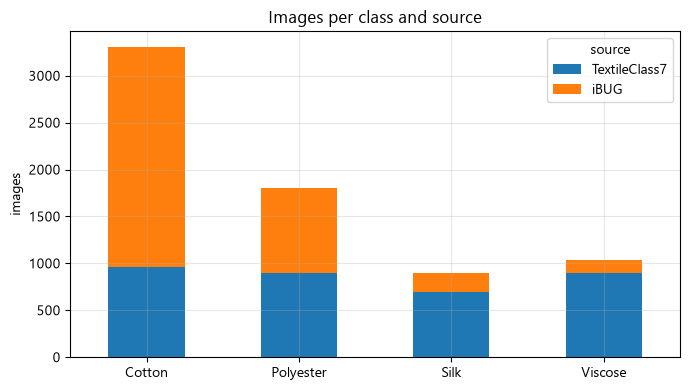

In [7]:
counts = pd.crosstab(manifest["class"], manifest["source"]).reindex(CLASSES).fillna(0).astype(int)
table = counts.copy()
table["Total"] = table.sum(axis=1)
table["Share"] = (table["Total"] / table["Total"].sum()).map("{:.1%}".format)
table.loc["Total"] = list(counts.sum()) + [counts.values.sum(), "100%"]
display(table)

fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.bar(stacked=True, ax=ax, rot=0)
ax.set(title="Images per class and source", xlabel="", ylabel="images")
savefig(fig, "eda_class_counts.png")
plt.show()

In [8]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 2.6 * len(CLASSES)))
for r, cls in enumerate(CLASSES):
    sub = manifest[(manifest["class"] == cls) & manifest["ok"]]
    pick = sub.sample(min(5, len(sub)), random_state=SEED)
    for c in range(5):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(pick):
            row = pick.iloc[c]
            img = fl.load_pil(DATA_DIR / row.path)
            img.thumbnail((256, 256))
            ax.imshow(img)
            ax.set_title(f"{cls} | {row.source}", fontsize=9)
fig.suptitle("Sample images (5 per class)")
savefig(fig, "eda_samples.png")
plt.show()

source        TextileClass7    iBUG
width  count         3439.0  3604.0
       mean           224.0   400.0
       std              0.0     0.0
       min            224.0   400.0
       25%            224.0   400.0
       50%            224.0   400.0
       75%            224.0   400.0
       max            224.0   400.0
height count         3439.0  3604.0
       mean           224.0   400.0
       std              0.0     0.0
       min            224.0   400.0
       25%            224.0   400.0
       50%            224.0   400.0
       75%            224.0   400.0
       max            224.0   400.0

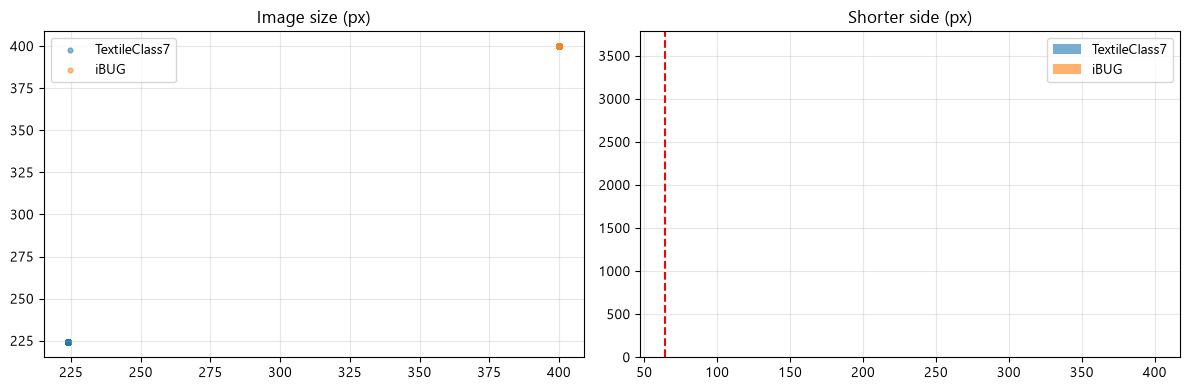

In [9]:
ok = manifest[manifest["ok"]].assign(min_side=lambda d: np.minimum(d.width, d.height))
display(ok.groupby("source")[["width", "height"]].describe().T.round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for src, g in ok.groupby("source"):
    axes[0].scatter(g.width, g.height, s=12, alpha=0.5, label=src)
axes[0].legend()
axes[0].set_title("Image size (px)")
for src, g in ok.groupby("source"):
    axes[1].hist(g.min_side, bins=40, alpha=0.6, label=src)
axes[1].legend()
axes[1].axvline(MIN_SIDE, color="red", ls="--", label=f"MIN_SIDE={MIN_SIDE}")
axes[1].set_title("Shorter side (px)")
savefig(fig, "eda_image_sizes.png")
plt.show()

## 3. Clean + Split

**ทำความสะอาด:** ลบภาพที่เปิดไม่ได้, ภาพที่ด้านใดด้านหนึ่งเล็กกว่า `MIN_SIDE` และภาพซ้ำ (md5 ของไฟล์เท่ากัน) ถ้าภาพซ้ำอยู่คนละคลาสจะลบทิ้งทั้งหมดเพราะไม่รู้ว่า label ไหนถูก

**ผลจากการตรวจคุณภาพ TextileClass-7** (`data_audit/`, ดูวิธีใน `audit_textileclass7.py`): ชื่อไฟล์บอกเครื่องและเวลาที่ถ่าย จึงหารูปของผ้าชิ้นเดียวกันได้จาก "เครื่องเดียวกัน + ถ่ายห่างไม่เกิน 10 วินาที + ภาพคล้ายกันมาก (cosine similarity ของ ResNet50 ≥ 0.90)"
- 136 คู่อยู่คลาสเดียวกันแต่ถูกนับเป็นคนละชิ้น → รวมเป็นชิ้นเดียว (1,433 → 1,308 ชิ้น) ตาม `fabric_groups.csv` เพื่อไม่ให้รั่วข้าม Train/Test
- 5 คู่เป็นผ้าชิ้นเดียวกันแต่ติด label คนละคลาส → ตัดออกทั้งสองฝั่งตาม `exclude.csv` (ตรวจด้วยตาแล้ว ดู `review_pairs.png`)
- ผ้าลายพิมพ์เดียวกันที่ถ่ายห่างกันเป็นชั่วโมงและสีต่างกัน (B3–B5) เก็บไว้ เพราะน่าจะเป็นลายเดียวกันที่พิมพ์บนผ้าคนละชนิด

**แบ่งข้อมูล 70/15/15 แบบ group-stratified:** ภาพจากชิ้นผ้าเดียวกัน (เช่น iBUG ที่ถ่ายชิ้นเดียวกันภายใต้แสงหลายทิศ) ต้องอยู่ชุดเดียวกันเสมอ และแต่ละชุดมีสัดส่วน class × source ใกล้เคียงกัน ใช้ `StratifiedGroupKFold` 20 fold แล้วรวม 14 fold เป็น Train, 3 เป็น Val, 3 เป็น Test

Augmentation ทำเฉพาะชุด Train ตอนเทรน (ส่วนที่ 4–7) หลังแบ่งแล้วเท่านั้น ต่างจาก R2 ที่ augment ก่อนแบ่งซึ่งทำให้ภาพเกือบซ้ำรั่วเข้าชุด Test

**จำนวนชิ้นจริงน้อยกว่าจำนวนไฟล์:** iBUG ถ่าย 1 ชิ้นภายใต้แสง 4 ทิศ (901 ชิ้น = 3,604 รูป) และ TextileClass-7 ถูก Roboflow augment ไว้แล้ว 3 เวอร์ชันต่อรูปในชุด train เดิม (3,439 ไฟล์ = รูปจริง 1,433 รูป) ถ้า `EVAL_ONE_PER_PIECE = True` Train จะใช้ทุกไฟล์ แต่ Val/Test เก็บไว้ 1 รูปต่อชิ้น (สุ่มด้วย seed) เพื่อไม่ให้ชิ้นเดียวกันถูกนับหลายครั้งตอนวัดผล

In [10]:
df = manifest.copy()
n0 = len(df)
bad = ~df["ok"]
small = df["ok"] & (np.minimum(df.width, df.height) < MIN_SIDE)
df = df[~bad & ~small]
n_cls_per_md5 = df.groupby("md5")["class"].nunique()
conflict = df["md5"].isin(n_cls_per_md5[n_cls_per_md5 > 1].index)
df = df[~conflict]
dup = df.duplicated("md5", keep="first")
df = df[~dup]
excluded = pd.Series(False, index=df.index)
if EXCLUDE_CSV.exists():
    exclude_groups = set(pd.read_csv(EXCLUDE_CSV)["photo_group"])
    photo_group = df["source"] + "/" + df["class"] + "/" + df["path"].map(
        lambda p: re.sub(GROUP_REGEX.get(p.split("/")[0]) or r"$^", "", Path(p).stem))
    excluded = photo_group.isin(exclude_groups)
    df = df[~excluded]
df = df.reset_index(drop=True)

display(pd.DataFrame({"count": {
    "ภาพทั้งหมด": n0, "เปิดไม่ได้ (เสีย)": int(bad.sum()), f"เล็กกว่า {MIN_SIDE}px": int(small.sum()),
    "ซ้ำแต่คนละคลาส (ลบทั้งหมด)": int(conflict.sum()), "ซ้ำในคลาสเดียวกัน (เก็บไว้ 1)": int(dup.sum()),
    f"label ขัดแย้งตาม {EXCLUDE_CSV.name}": int(excluded.sum()), "คงเหลือ": len(df)}}))

pieces = df.groupby("source").agg(images=("path", "size"), pieces=("sample_id", "nunique"))
pieces["images_per_piece"] = (pieces.images / pieces.pieces).round(2)
display(pieces)
if "iBUG" in pieces.index and pieces.loc["iBUG", "images_per_piece"] <= 1.0:
    warnings.warn("iBUG มี 1 รูปต่อ 1 ชิ้นผ้า ถ้าชิ้นเดียวกันถูกถ่ายหลายรูป (หลายทิศแสง) ให้ตั้ง "
                  "GROUP_REGEX['iBUG'] ใน Config มิฉะนั้นภาพของชิ้นเดียวกันอาจรั่วข้ามชุด Train/Test")

,count
ภาพทั้งหมด,7043
เปิดไม่ได้ (เสีย),0
เล็กกว่า 64px,0
ซ้ำแต่คนละคลาส (ลบทั้งหมด),0
ซ้ำในคลาสเดียวกัน (เก็บไว้ 1),44
label ขัดแย้งตาม exclude.csv,26
คงเหลือ,6973


,images,pieces,images_per_piece
source,,,
TextileClass7,3413,1298,2.63
iBUG,3560,890,4.00


In [11]:
SPLIT_PATH = SPLIT_DIR / "split.csv"
N_FOLDS = 20

split_df = None
if SPLIT_PATH.exists():
    old = pd.read_csv(SPLIT_PATH)
    # ใช้ของเดิมได้เฉพาะเมื่อรูปและการจัดกลุ่มชิ้นผ้าเหมือนเดิมทุกประการ
    if set(zip(old.path, old.sample_id)) == set(zip(df.path, df.sample_id)):
        split_df = df.merge(old[["path", "split"]], on="path")
        print("ใช้การแบ่งข้อมูลเดิมจาก", SPLIT_PATH.name)
    else:
        print("ข้อมูลเปลี่ยนจาก split.csv เดิม จะแบ่งใหม่")
if split_df is None:
    strata = df["class"] + "|" + df["source"]
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    fold = np.empty(len(df), dtype=int)
    for k, (_, idx) in enumerate(sgkf.split(df, strata, groups=df["sample_id"])):
        fold[idx] = k
    n_tr, n_va = round(N_FOLDS * SPLIT[0]), round(N_FOLDS * SPLIT[1])
    split_df = df.assign(split=np.select([fold < n_tr, fold < n_tr + n_va], ["train", "val"], "test"))
    split_df[["path", "class", "source", "sample_id", "split"]].to_csv(SPLIT_PATH, index=False)
    print("บันทึก", SPLIT_PATH)

leak = split_df.groupby("sample_id")["split"].nunique()
assert (leak == 1).all(), f"มีชิ้นผ้า {int((leak > 1).sum())} ชิ้นอยู่มากกว่าหนึ่งชุด"
print("ตรวจแล้ว: ไม่มีชิ้นผ้าซ้ำข้ามชุด Train/Val/Test")

if EVAL_ONE_PER_PIECE:
    is_eval = split_df["split"] != "train"
    one = split_df[is_eval].sort_values("path").groupby("sample_id").sample(1, random_state=SEED)
    print(f"Val/Test: เก็บ 1 รูปต่อชิ้น {len(one):,} จาก {int(is_eval.sum()):,} รูป")
    split_df = pd.concat([split_df[~is_eval], one])
split_df = split_df.sort_values("path").reset_index(drop=True)

y_all = split_df["class"].map(CLASS_TO_IDX).to_numpy()
g_all = split_df["sample_id"].to_numpy()
masks = {s: (split_df["split"] == s).to_numpy() for s in ("train", "val", "test")}

summary = pd.crosstab([split_df["source"], split_df["class"]], split_df["split"])[["train", "val", "test"]]
summary.loc[("All", "All"), :] = summary.sum()
display(summary.assign(**{"train %": lambda d: (d.train / d.sum(axis=1)).map("{:.0%}".format)}))

ใช้การแบ่งข้อมูลเดิมจาก split.csv
ตรวจแล้ว: ไม่มีชิ้นผ้าซ้ำข้ามชุด Train/Val/Test
Val/Test: เก็บ 1 รูปต่อชิ้น 654 จาก 2,086 รูป


split                     train    val   test train %
source        class                                  
TextileClass7 Cotton      665.0   52.0   54.0     86%
              Polyester   620.0   49.0   51.0     86%
              Silk        489.0   40.0   38.0     86%
              Viscose     617.0   52.0   52.0     86%
iBUG          Cotton     1624.0   87.0   87.0     90%
              Polyester   620.0   34.0   34.0     90%
              Silk        148.0    6.0    7.0     92%
              Viscose     104.0    6.0    5.0     90%
All           All        4887.0  326.0  328.0     88%

In [12]:
# ตรวจข้อมูลก่อนเทรน: จำนวนรูปต้องเท่ากับที่ใช้ในเวอร์ชันก่อน เพื่อให้ผลเทียบกันได้
if SMOKE:
    rng_s = np.random.default_rng(SEED)
    keep = np.zeros(len(split_df), dtype=bool)
    for (s, c), idx in split_df.groupby(["split", "class"]).indices.items():
        n = SMOKE_PER_CLASS if s == "train" else SMOKE_PER_CLASS // 3
        keep[rng_s.choice(idx, min(n, len(idx)), replace=False)] = True
    split_df = split_df[keep].reset_index(drop=True)
    y_all = split_df["class"].map(CLASS_TO_IDX).to_numpy()
    masks = {s: (split_df["split"] == s).to_numpy() for s in ("train", "val", "test")}
    print("SMOKE: ใช้ข้อมูลส่วนน้อย", {s: int(m.sum()) for s, m in masks.items()})

y_tr, y_va, y_te = (y_all[masks[s]] for s in ("train", "val", "test"))
N_IMAGES = tuple(int(masks[s].sum()) for s in ("train", "val", "test"))
if not SMOKE and N_IMAGES != (4887, 326, 328):
    raise RuntimeError(f"จำนวนรูป Train/Val/Test = {N_IMAGES} ไม่ตรงกับเวอร์ชันก่อน (4887, 326, 328): "
                       "ข้อมูลหรือ split.csv เปลี่ยนไป ผลจะเทียบกับเวอร์ชันก่อนไม่ได้")

# fingerprint ของข้อมูล: run ที่บันทึกไว้จะถูกใช้ซ้ำเฉพาะเมื่อข้อมูลชุดเดียวกัน
FINGERPRINT = hashlib.md5(json.dumps({"split": split_df[["path", "split"]].values.tolist(),
                                      "seed": SEED}).encode()).hexdigest()[:12]
print(f"train {N_IMAGES[0]:,} | val {N_IMAGES[1]:,} | test {N_IMAGES[2]:,} | data fingerprint {FINGERPRINT}")

train 4,887 | val 326 | test 328 | data fingerprint 8f66afa23ba6


## 4. ฟังก์ชันเทรนและวัดผลร่วม

ทุกขั้น (คัดเลือก, ก่อนจูน, trial ของ Optuna, หลังจูน) ใช้ฟังก์ชันเทรนเดียวกัน `train_one(arch, params, seed, max_epochs, stage)`

**สูตรเทรนแบบ 2 เฟส (transfer learning มาตรฐาน)**
1. **เฟส 1 (head):** แช่แข็ง backbone ที่ pretrain บน ImageNet แล้วเทรนเฉพาะหัวจำแนก `head_epochs` epoch ด้วย lr `lr_head`
2. **เฟส 2 (fine-tune):** เปิดให้เทรน layer บนสุด `unfreeze_frac` ของ backbone ด้วย lr `lr_ft` ที่ลดแบบ cosine
   สูงสุด `MAX_EPOCHS` epoch และหยุดเมื่อ Val Macro-F1 ไม่ดีขึ้น `PATIENCE` epoch แล้วใช้ weights ของ epoch ที่ดีที่สุด

BatchNorm แช่แข็งเสมอ (ใช้ค่าสถิติจาก ImageNet) loss เป็น cross-entropy ถ่วงน้ำหนักตามสัดส่วนคลาส ใช้ mixed precision (AMP)
และ AdamW ทุก run ถูกบันทึกด้วย `run_id` (hash ของโมเดล + hyperparameter + seed + epoch + ข้อมูล) รันซ้ำจะโหลดของเดิม

**สูตร default** (`DEFAULT_PARAMS`): lr_head 1e-3, lr_ft 1e-5, เปิด 30% บนสุด, เฟส 1 3 epoch, dropout 0.3,
weight decay 1e-4, ไม่มี label smoothing, ไม่มี MixUp/CutMix และ augmentation ตามรอบ (none / v1 / v2)

In [13]:
"""ฟังก์ชันช่วยของ notebook ส่วน 6–10 (ถูกฝังลง notebook โดย tools/build_notebook.py)"""
from __future__ import annotations

import numpy as np

# รอบเทรนตามสไลด์: 1 ไม่ทำ augmentation, 2 augmentation แบบเบา (v1), 3 แบบหนัก (v2)
# + รอบ 4 texture: augmentation ที่รักษาพื้นผิวผ้า (ไม่มี blur / noise / หมุนเอียง)
ROUNDS = ["none", "v1", "v2", "texture"]  # list (ไม่ใช่ tuple) เพื่อใช้ df[ROUNDS] ได้
# สูตร default ของรอบคัดเลือก (aug ถูกแทนด้วยรอบนั้น ๆ)
DEFAULT_PARAMS = dict(lr_head=1e-3, lr_ft=1e-5, unfreeze_frac=0.3, head_epochs=3, dropout=0.3,
                      weight_decay=1e-4, label_smoothing=0.0, aug="none", mixup=False)


def suggest_params(trial) -> dict:
    """search space ของ Optuna (ตาม spec)"""
    return dict(
        lr_head=trial.suggest_float("lr_head", 1e-4, 3e-3, log=True),
        lr_ft=trial.suggest_float("lr_ft", 1e-6, 1e-4, log=True),
        unfreeze_frac=trial.suggest_float("unfreeze_frac", 0.1, 1.0),
        head_epochs=trial.suggest_int("head_epochs", 1, 5),
        dropout=trial.suggest_float("dropout", 0.0, 0.5),
        weight_decay=trial.suggest_float("weight_decay", 1e-5, 0.05, log=True),
        label_smoothing=trial.suggest_float("label_smoothing", 0.0, 0.15),
        aug=trial.suggest_categorical("aug", list(ROUNDS)),
        mixup=trial.suggest_categorical("mixup", [False, True]),
    )


def make_sampler(n_existing: int, seed: int = 42):
    """TPE ที่ seed ขึ้นกับจำนวน trial ที่มีอยู่แล้ว: รันต่อหลังหยุดกลางทางจะไม่สุ่มค่าซ้ำกับ trial เดิม
    n_startup_trials=5 (สุ่ม 5 trial แรก ที่เหลือให้ TPE เลือกจากผลก่อนหน้า)"""
    import optuna

    return optuna.samplers.TPESampler(seed=seed + n_existing, n_startup_trials=5)


def check_export(p_app, p_nb, max_mismatch: int = 1, warn_diff: float = 1e-2) -> tuple[bool, str]:
    """เทียบ probability จากแอป (load_predictor) กับ notebook: fp16 + batch ต่างกันทำให้ต่างเล็กน้อยได้
    ไม่ผ่านเมื่อคลาสที่ทายต่างกันเกิน max_mismatch รูป"""
    p_app, p_nb = np.asarray(p_app), np.asarray(p_nb)
    diff = float(np.abs(p_app - p_nb).max())
    mism = int((p_app.argmax(1) != p_nb.argmax(1)).sum())
    msg = f"max diff {diff:.1e}, argmax ต่างกัน {mism}/{len(p_app)} รูป"
    if mism > max_mismatch:
        return False, msg
    if diff > warn_diff:
        msg += " (ต่างมากกว่าปกติ ควรตรวจ preprocessing)"
    return True, msg


def wait_for_cool(read_temp, pause_at: float = 60, resume_at: float = 50, sleep=None, poll_s: float = 5) -> float:
    """ถ้าการ์ดจอร้อนถึง pause_at °C ให้หยุดรอจนเย็นลงถึง resume_at °C (คืนจำนวนวินาทีที่พัก)
    อ่านอุณหภูมิไม่ได้ (เช่นไม่มี GPU) -> ไม่พัก"""
    import time

    sleep = sleep or time.sleep
    try:
        if read_temp() < pause_at:
            return 0
        waited = 0
        while read_temp() > resume_at:
            sleep(poll_s)
            waited += poll_s
        return waited
    except Exception:
        return 0


def fail_stale_trials(study) -> int:
    """trial ที่ค้างสถานะ RUNNING (kernel ตาย/ถูกหยุดกลาง trial) -> FAIL เพื่อไม่ให้ค้างในผลและใน TPE"""
    import optuna

    stale = [t.number for t in study.trials if t.state == optuna.trial.TrialState.RUNNING]
    for n in stale:
        study.tell(n, state=optuna.trial.TrialState.FAIL)
    return len(stale)


def remaining_trials(study, n_total: int) -> int:
    """จำนวน trial ที่ยังต้องรัน (นับ trial ที่จบแล้วทุกสถานะ) ใช้ต่อการจูนที่ค้างไว้"""
    import optuna

    done = {optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED, optuna.trial.TrialState.FAIL}
    return max(0, n_total - sum(t.state in done for t in study.trials))


def select_top1(df, tol: float = 0.01) -> str:
    """Val Macro-F1 สูงสุด; ถ้าตัวอื่นต่างไม่เกิน tol เลือกตัวที่ inference เร็วที่สุดในกลุ่มนั้น
    คืนค่า candidate = "<arch>|<round>" """
    best = df["val_macro_f1"].max()
    close = df[df["val_macro_f1"] >= best - tol - 1e-12].copy()
    # ความเร็วเป็นคุณสมบัติของสถาปัตยกรรม: ใช้ค่ามัธยฐานต่อ arch ปัดเป็น ms เต็ม เพื่อไม่ให้เศษ ms ตัดสิน
    arch = df["candidate"].str.split("|").str[0]
    speed = df.assign(arch=arch).groupby("arch")["infer_ms_per_img"].median().round()
    close["speed"] = close["candidate"].str.split("|").str[0].map(speed)
    return str(close.sort_values(["speed", "val_macro_f1"], ascending=[True, False])["candidate"].iloc[0])


def diagnose_fit(history, train_acc_eval: float | None = None) -> str:
    """วินิจฉัย overfitting จากช่องว่าง train−val accuracy ที่ epoch ที่ Val Macro-F1 ดีที่สุด
    train_acc_eval = accuracy ของชุด Train แบบ eval mode ไม่มี augmentation (ถ้ามีให้ใช้ค่านี้ เพราะ train accuracy
    ระหว่างเทรนวัดบนภาพที่ผ่าน augmentation/MixUp แล้ว จึงต่ำกว่าจริง)"""
    best = max(history, key=lambda h: h["val_macro_f1"])
    train_acc = best["train_accuracy"] if train_acc_eval is None else train_acc_eval
    gap = 100 * (train_acc - best["val_accuracy"])
    level = "ปกติ" if gap < 5 else ("overfitting เล็กน้อย" if gap <= 15 else "overfitting สูง")
    return f"{level} | best epoch {best['epoch']} | train−val accuracy gap {gap:.1f} จุด"


def bootstrap_ci(y, pred, B: int = 1000, seed: int = 42, n_classes: int = 4) -> tuple[float, float]:
    """ช่วงความเชื่อมั่น 95% ของ Macro-F1 ด้วย bootstrap (สุ่มรูปซ้ำแบบใส่คืน)"""
    from sklearn.metrics import f1_score

    y, pred = np.asarray(y), np.asarray(pred)
    idx = np.random.default_rng(seed).integers(0, len(y), size=(B, len(y)))
    f1s = [f1_score(y[i], pred[i], labels=range(n_classes), average="macro", zero_division=0) for i in idx]
    lo, hi = np.percentile(f1s, [2.5, 97.5])
    return float(lo), float(hi)


def mcnemar(y, pred_a, pred_b) -> tuple[int, int, float]:
    """b = a ถูก b ผิด, c = a ผิด b ถูก, p = exact binomial test (two-sided)"""
    from scipy.stats import binomtest

    ok_a, ok_b = np.asarray(pred_a) == np.asarray(y), np.asarray(pred_b) == np.asarray(y)
    b, c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return b, c, float(binomtest(b, b + c, 0.5).pvalue) if b + c else 1.0

In [14]:
RUNS_CSV = RESULTS_DIR / "runs.csv"
# เพิ่มเลขนี้เมื่อแก้โค้ดเทรน (_fit / fabric_lib) run ที่ cache จากเวอร์ชันก่อนจะมีคำเตือน
# (ถ้าต้องการเทรนใหม่ทั้งหมด ให้ลบ models/runs/ และ results/histories/)
CODE_VERSION = 3
counts = np.bincount(y_tr, minlength=len(CLASSES))
CLASS_W = counts.sum() / (len(CLASSES) * np.maximum(counts, 1))
print("class weights:", dict(zip(CLASSES, CLASS_W.round(2))))
_PROBA_CACHE = {}


def make_loader(split, train, batch_size, aug="none", seed=SEED):
    m = masks[split]
    ds = fl.FabricDataset([DATA_DIR / p for p in split_df["path"][m]], y_all[m], train=train, aug=aug)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=train, drop_last=train,
                                       num_workers=NUM_WORKERS, pin_memory=USE_AMP,
                                       persistent_workers=NUM_WORKERS > 0,
                                       generator=torch.Generator().manual_seed(seed))


COOL_LOG = {"pauses": 0, "seconds": 0}


def cool_gpu():
    """ถ้าการ์ดจอถึง GPU_TEMP_PAUSE °C ให้หยุดรอจนเย็นถึง GPU_TEMP_RESUME °C (กันการ์ดจอร้อนสะสมจนไดรเวอร์หลุด)"""
    if not USE_AMP or GPU_TEMP_PAUSE is None:
        return
    waited = wait_for_cool(torch.cuda.temperature, GPU_TEMP_PAUSE, GPU_TEMP_RESUME)
    if waited:
        COOL_LOG["pauses"] += 1
        COOL_LOG["seconds"] += waited
        print(f"  พักการ์ดจอ {waited:.0f} วินาที (ถึง {GPU_TEMP_PAUSE}°C) รวม {COOL_LOG['pauses']} ครั้ง "
              f"{COOL_LOG['seconds'] / 60:.0f} นาที")


@torch.inference_mode()
def predict_model(model, loader):
    model.eval()
    out = []
    for i, (x, _) in enumerate(loader):
        if i % 10 == 0:
            cool_gpu()
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x.to(DEVICE, non_blocking=True))
        out.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(out)


def ce_loss(y, proba):
    """cross-entropy เฉลี่ย (ไม่ถ่วงน้ำหนัก) จาก probability"""
    return float(-np.log(np.clip(np.asarray(proba)[np.arange(len(y)), y], 1e-7, 1)).mean())


def run_id_of(arch, params, seed, max_epochs, trial=False):
    key = {"arch": arch, "params": params, "seed": seed, "max_epochs": max_epochs, "data": FINGERPRINT}
    if trial:  # trial ไม่เก็บ weights จึงแยก id จาก run เต็มที่ใช้ค่าเดียวกัน
        key["trial"] = True
    return hashlib.md5(json.dumps(key, sort_keys=True, default=str).encode()).hexdigest()[:12]


def _fit(arch, params, seed, max_epochs, batch_size, trial=None):
    """เทรน 2 เฟส -> (state_dict ที่ดีที่สุด, history, val metrics ของ epoch ที่ดีที่สุด, วินาที, จำนวนพารามิเตอร์)"""
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    model = fl.build_model(arch, dropout=params["dropout"], pretrained=True).to(DEVICE)
    train_loader = make_loader("train", True, batch_size, params["aug"], seed)
    val_loader = make_loader("val", False, 64, seed=seed)
    cw = torch.tensor(CLASS_W, dtype=torch.float32, device=DEVICE)
    ls = float(params["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history, best_f1, best_state, best_vm, epoch = [], -1.0, None, None, 0
    t0 = time.perf_counter()
    phases = [("head", int(params["head_epochs"]), params["lr_head"], 0.0),
              ("finetune", int(max_epochs), params["lr_ft"], params["unfreeze_frac"])]
    for phase, n_epochs, lr, frac in phases:
        fl.set_trainable(model, frac)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr,
                                weight_decay=params["weight_decay"])
        total_steps, step, wait = max(1, n_epochs * len(train_loader)), 0, 0
        for e in range(n_epochs):
            epoch += 1
            fl.train_mode(model)
            tot, n, correct = 0.0, 0, 0
            for x, y in train_loader:
                if step % 10 == 0:
                    cool_gpu()
                x = x.to(DEVICE, non_blocking=True)
                target = F.one_hot(y.to(DEVICE), len(CLASSES)).float()
                if params["mixup"]:
                    x, target = fl.mix_batch(x, target, rng)
                if phase == "finetune":  # cosine decay ภายในเฟส fine-tune
                    opt.param_groups[0]["lr"] = lr * 0.5 * (1 + math.cos(math.pi * step / total_steps))
                step += 1
                soft = target * (1 - ls) + ls / len(CLASSES)
                with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    logits = model(x)
                w = target @ cw
                loss = (-(soft * F.log_softmax(logits.float(), dim=1)).sum(1) * w).sum() / w.sum()
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(x)
                correct += (logits.argmax(1) == y.to(DEVICE)).sum().item()
                n += len(x)
            vp = predict_model(model, val_loader)
            vm = evaluate(y_va, vp)
            history.append({"epoch": epoch, "phase": phase, "train_loss": tot / max(n, 1),
                            "train_accuracy": correct / max(n, 1), "val_loss": ce_loss(y_va, vp),
                            "val_accuracy": vm["accuracy"], "val_macro_f1": vm["macro_f1"],
                            "lr": opt.param_groups[0]["lr"]})
            improved = vm["macro_f1"] > best_f1 + 1e-4
            print(f"  epoch {epoch:2d} [{phase:8s}] loss {tot / max(n, 1):.3f} | val acc {vm['accuracy']:.3f} "
                  f"F1 {vm['macro_f1']:.3f}{'  *' if improved else ''} | {time.perf_counter() - t0:.0f}s")
            if improved:
                best_f1, best_vm, wait = vm["macro_f1"], vm, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            elif phase == "finetune":
                wait += 1
            if trial is not None and phase == "finetune":
                trial.report(vm["macro_f1"], e)
                if trial.should_prune():
                    raise optuna.TrialPruned()
            if phase == "finetune" and wait >= PATIENCE:
                print(f"  early stopping (Val Macro-F1 ไม่ดีขึ้น {PATIENCE} epoch)")
                break
    n_params = sum(p.numel() for p in model.parameters())
    return best_state, history, best_vm, time.perf_counter() - t0, n_params


def load_run(run_id):
    return json.loads((HIST_DIR / f"{run_id}.json").read_text(encoding="utf-8"))


def train_one(arch, params, seed, max_epochs, stage, trial=None):
    """เทรน (หรือโหลดถ้ามีแล้ว) 1 run -> run_id; trial ของ Optuna เก็บเฉพาะ history ไม่เก็บ weights"""
    rid = run_id_of(arch, params, seed, max_epochs, trial=stage == "trial")
    hist_path, w_path = HIST_DIR / f"{rid}.json", RUNS_DIR / f"{rid}.pth"
    if SKIP_TRAINING_IF_EXISTS and hist_path.exists() and (stage == "trial" or w_path.exists()):
        r = load_run(rid)
        print(f"โหลด {arch} seed {seed} ({stage}) จาก run {rid}: Val Macro-F1 {r['val_metrics']['macro_f1']:.3f}")
        if r.get("code_version") != CODE_VERSION:
            warnings.warn(f"run {rid} เทรนด้วยโค้ดเวอร์ชัน {r.get('code_version')} แต่ตอนนี้เป็น {CODE_VERSION}: "
                          "ถ้าแก้โค้ดเทรน ให้ลบ models/runs/ และ results/histories/ แล้วรันใหม่")
        return rid
    print(f"เทรน {fl.TV_ZOO[arch]['name']} | {stage} | seed {seed} | run {rid}")
    for bs in dict.fromkeys((BATCH_SIZE, 16)):
        try:
            state, history, vm, secs, n_params = _fit(arch, params, seed, max_epochs, bs, trial)
            break
        except torch.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"GPU out-of-memory ที่ batch {bs} ลอง batch ที่เล็กลง")
    else:
        raise RuntimeError("GPU memory ไม่พอแม้ใช้ batch 16")
    if stage != "trial":
        torch.save(state, w_path)
    record = {"run_id": rid, "arch": arch, "stage": stage, "seed": seed, "max_epochs": max_epochs, "params": params,
              "batch_size": bs, "history": history, "val_metrics": vm, "train_time_s": secs, "n_params": n_params,
              "epochs_trained": len(history), "data_fingerprint": FINGERPRINT, "code_version": CODE_VERSION}
    hist_path.write_text(json.dumps(record, indent=1, default=str), encoding="utf-8")
    row = {"run_id": rid, "stage": stage, "arch": arch, "seed": seed, "max_epochs": max_epochs, "batch_size": bs,
           **{f"p_{k}": v for k, v in params.items()}, **{f"val_{k}": v for k, v in vm.items()},
           "train_time_s": round(secs, 1), "epochs_trained": len(history)}
    pd.DataFrame([row]).to_csv(RUNS_CSV, mode="a", header=not RUNS_CSV.exists(), index=False)
    print(f"-> Val Macro-F1 {vm['macro_f1']:.3f} | Acc {vm['accuracy']:.3f} | {secs / 60:.1f} นาที")
    torch.cuda.empty_cache()
    return rid


def load_model(run_id):
    r = load_run(run_id)
    model = fl.build_model(r["arch"], dropout=r["params"]["dropout"], pretrained=False)
    model.load_state_dict(torch.load(RUNS_DIR / f"{run_id}.pth", map_location="cpu", weights_only=True))
    return model.to(DEVICE).eval()


def predict_split(run_id, split):
    """probability (n, 4) ของ run บนชุด val/test (cache ไว้ในหน่วยความจำ)"""
    if (run_id, split) not in _PROBA_CACHE:
        _PROBA_CACHE[(run_id, split)] = predict_model(load_model(run_id), make_loader(split, False, 64))
    return _PROBA_CACHE[(run_id, split)]


def time_inference(run_id, n=50):
    """เวลา end-to-end ต่อ 1 รูป (อ่านไฟล์ + preprocessing + ทำนาย) ด้วย predictor ตัวเดียวกับแอป, ค่ามัธยฐาน"""
    pred = fl.TorchPredictor(load_model(run_id), DEVICE)
    sample = [DATA_DIR / p for p in split_df["path"][masks["val"]].iloc[:n]]
    pred.predict_proba(sample[:2])
    times = []
    for p in sample:
        t0 = time.perf_counter()
        pred.predict_proba([p])
        times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times))


def plot_history(run_ids, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for label, rid in run_ids.items():
        h = pd.DataFrame(load_run(rid)["history"])
        axes[0].plot(h.epoch, h.train_loss, marker=".", label=label)
        axes[1].plot(h.epoch, h.val_macro_f1, marker=".", label=label)
    axes[0].set(title=f"{title}: train loss", xlabel="epoch")
    axes[1].set(title=f"{title}: Val Macro-F1", xlabel="epoch")
    axes[1].legend()
    savefig(fig, fname)
    plt.show()


def plot_cm(ax, cm, counts_only=False):
    """confusion matrix ด้วย matplotlib: สีตามสัดส่วนของคลาสจริง ตัวเลขเป็นจำนวน (และ %)"""
    norm = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            txt = f"{cm[i, j]}" if counts_only else f"{cm[i, j]}\n{norm[i, j]:.0%}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9, color="white" if norm[i, j] > 0.5 else "black")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="predicted", ylabel="true")
    ax.grid(False)

class weights: {'Cotton': np.float64(0.53), 'Polyester': np.float64(0.99), 'Silk': np.float64(1.92), 'Viscose': np.float64(1.69)}


## 5. รอบเทรน: 4 โมเดล × 4 รอบ (สูตร default, seed 42)

| # | โมเดล | ประเภท | พารามิเตอร์ | ปี | ทำไมเลือก |
|---|---|---|---|---|---|
| 1 | **ResNet50** | CNN แบบ residual | ~25M | 2015 | baseline ตาม PRD และ R3 (ResNet50 ดีที่สุดในงานจำแนกผ้า) |
| 2 | **DenseNet121** | CNN แบบ dense connection | ~8M | 2017 | R3 ใช้เปรียบเทียบ, ใช้ฟีเจอร์ระดับต่ำซ้ำได้ดี (เหมาะกับพื้นผิว) |
| 3 | **EfficientNet-B0** | CNN ที่ปรับขนาดอย่างสมดุล | ~5M | 2019 | เล็กและเร็ว |
| 4 | **ConvNeXt-Tiny** | CNN ยุคใหม่ (ออกแบบตาม transformer) | ~28M | 2022 | CNN ที่แรงที่สุดที่ยังพอดีกับ GPU 6 GB |

**3 รอบต่อโมเดล (ตามสไลด์ตัวอย่างของวิชา)** เปลี่ยนเฉพาะ augmentation ของชุด Train ส่วนอื่นเหมือนกันทุกรอบ

| รอบ | augmentation |
|---|---|
| 1. none | ไม่ทำอะไร (ย่อรูป + ครอปกลาง เหมือนตอนวัดผล) |
| 2. v1 (เบา) | กลับด้านแนวนอน, หมุน ±10.8°, เลื่อน 5%, noise 2%, blur 30% |
| 3. v2 (หนัก) | กลับด้านแนวนอน, หมุน ±21.6°, เลื่อน 8%, ความสว่าง/คอนทราสต์ ±10%, noise 5%, blur 50% |
| 4. texture | **เพิ่มเติม:** สุ่มครอป 40–100%, หมุนทีละ 90°, กลับด้าน, ปรับสีเล็กน้อย (ไม่มี blur / noise / หมุนเอียง) |

รอบ 4 เพิ่มเข้ามาหลังพบว่า v1/v2 ทำให้ทุกโมเดลแย่ลง: blur และ noise ลบรายละเอียดลายเส้นใยที่ใช้แยกชนิดผ้า
และการหมุนเอียงทำให้เกิดขอบดำ ส่วน texture เป็น augmentation ที่ใช้ในเวอร์ชันก่อน (ResNet50 ได้ Val 0.807)

ตารางขนาดโมเดลมีขนาดไฟล์ (MB), จำนวนพารามิเตอร์ และความแม่นยำ ImageNet Top-1/Top-5 ของ weights ที่ใช้ (จาก torchvision)

โหลด resnet50 seed 42 (screening) จาก run 6bc9a4c4c8dc: Val Macro-F1 0.746
โหลด resnet50 seed 42 (screening) จาก run eae732cec1b2: Val Macro-F1 0.694
โหลด resnet50 seed 42 (screening) จาก run ace4e1e7b80e: Val Macro-F1 0.641
โหลด resnet50 seed 42 (screening) จาก run 70503d0eafaa: Val Macro-F1 0.804
โหลด densenet121 seed 42 (screening) จาก run 46b29de01514: Val Macro-F1 0.768
โหลด densenet121 seed 42 (screening) จาก run a34c3e5f177f: Val Macro-F1 0.570
โหลด densenet121 seed 42 (screening) จาก run 32138c14aa82: Val Macro-F1 0.514
โหลด densenet121 seed 42 (screening) จาก run 3f2f25a807b1: Val Macro-F1 0.752
โหลด efficientnet_b0 seed 42 (screening) จาก run e211fa47f4e3: Val Macro-F1 0.740
โหลด efficientnet_b0 seed 42 (screening) จาก run 709d0cc2131d: Val Macro-F1 0.638
โหลด efficientnet_b0 seed 42 (screening) จาก run cb0d0ad37d8f: Val Macro-F1 0.561
โหลด efficientnet_b0 seed 42 (screening) จาก run 5702b432c844: Val Macro-F1 0.710
โหลด convnext_tiny seed 42 (screening) จาก run fe9354840d00:

round,none,v1,v2,texture
model,,,,
ConvNeXt-Tiny,0.790,0.690,0.624,0.790
DenseNet121,0.768,0.570,0.514,0.752
EfficientNet-B0,0.740,0.638,0.561,0.710
ResNet50,0.746,0.694,0.641,0.804


,size_mb,params_M,imagenet_top1,imagenet_top5,infer_ms_per_img
model,,,,,
ResNet50,90.00,23.52,80.86,95.43,8.08
DenseNet121,27.09,6.96,74.43,91.97,24.37
EfficientNet-B0,15.57,4.01,77.69,93.53,14.86
ConvNeXt-Tiny,106.19,27.82,82.52,96.15,12.63


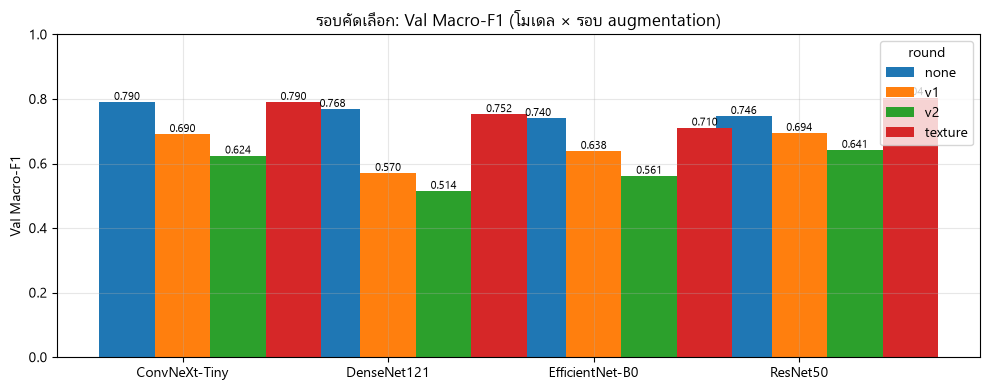

In [15]:
SCREEN_RUNS = {(arch, r): train_one(arch, {**DEFAULT_PARAMS, "aug": r}, SEED, MAX_EPOCHS, "screening")
               for arch in MODEL_KEYS for r in ROUNDS}

rows = []
for (arch, r), rid in SCREEN_RUNS.items():
    run, vm = load_run(rid), load_run(rid)["val_metrics"]
    top1, top5 = fl.imagenet_metrics(arch)
    rows.append({"model": fl.TV_ZOO[arch]["name"], "arch": arch, "round": r, "candidate": f"{arch}|{r}", "run_id": rid,
                 **{f"val_{k}": vm[k] for k in ("accuracy", "macro_precision", "macro_recall", "macro_f1", "min_recall")},
                 **{f"recall_{c}": vm[f"recall_{c}"] for c in CLASSES},
                 "params_M": run["n_params"] / 1e6, "size_mb": (RUNS_DIR / f"{rid}.pth").stat().st_size / 2**20,
                 "imagenet_top1": top1, "imagenet_top5": top5,
                 "train_time_s": run["train_time_s"], "epochs_trained": run["epochs_trained"],
                 "train_accuracy_eval": (tr_acc := evaluate(y_tr, predict_split(rid, "train"))["accuracy"]),
                 "fit": diagnose_fit(run["history"], tr_acc), "infer_ms_per_img": time_inference(rid)})
screening = pd.DataFrame(rows)
screening.to_csv(RESULTS_DIR / "screening.csv", index=False)
display(screening.pivot(index="model", columns="round", values="val_macro_f1")[ROUNDS].round(3))
display(screening.drop_duplicates("model")[["model", "size_mb", "params_M", "imagenet_top1", "imagenet_top5", "infer_ms_per_img"]]
        .set_index("model").round(2))

fig, ax = plt.subplots(figsize=(10, 4))
piv = screening.pivot(index="model", columns="round", values="val_macro_f1")[ROUNDS]
for k, r in enumerate(ROUNDS):
    bars = ax.bar(np.arange(len(piv)) + (k - 1) * 0.27, piv[r], width=0.27, label=r)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set(xticks=np.arange(len(piv)), xticklabels=piv.index, ylim=(0, 1), ylabel="Val Macro-F1",
       title="รอบคัดเลือก: Val Macro-F1 (โมเดล × รอบ augmentation)")
ax.legend(title="round")
savefig(fig, "screening_rounds.png")
plt.show()

## 6. เลือก Top 1 (โมเดล + รอบ)

**เกณฑ์ (กำหนดไว้ล่วงหน้าใน PRD):** Val Macro-F1 สูงสุดจากทั้ง 16 run ถ้าตัวอื่นต่างไม่เกิน 0.01 เลือกตัวที่ inference เร็วกว่า
ชุด Test และ Unseen ยังไม่ถูกใช้ในขั้นนี้

ฟังก์ชันช่วยของส่วน 6–10 (search space ของ Optuna, เกณฑ์เลือก, วินิจฉัย overfitting, bootstrap CI, McNemar) อยู่ใน cell ด้านล่าง

In [16]:
TOP1_CANDIDATE = select_top1(screening)
TOP1, TOP1_ROUND = TOP1_CANDIDATE.split("|")
TOP1_PARAMS = {**DEFAULT_PARAMS, "aug": TOP1_ROUND}
TOP1_NAME = fl.TV_ZOO[TOP1]["name"]
best_f1 = screening.val_macro_f1.max()
selection = {"top1_arch": TOP1, "top1_round": TOP1_ROUND, "top1_name": TOP1_NAME, "top1_candidate": TOP1_CANDIDATE,
             "rule": "max Val Macro-F1 over model x round; within 0.01 -> faster inference (ms/img)",
             "candidates_within_0.01": screening.loc[screening.val_macro_f1 >= best_f1 - 0.01, "candidate"].tolist(),
             "val_macro_f1": dict(zip(screening.candidate, screening.val_macro_f1)),
             "infer_ms_per_img": dict(zip(screening.candidate, screening.infer_ms_per_img))}
(RESULTS_DIR / "selection.json").write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding="utf-8")
display(screening.sort_values("val_macro_f1", ascending=False)[["model", "round", "val_macro_f1", "val_accuracy",
                                                                 "fit", "infer_ms_per_img"]].round(3))
print(f"Top 1 = {TOP1_NAME} รอบ {TOP1_ROUND} (กลุ่มที่ต่างไม่เกิน 0.01: {selection['candidates_within_0.01']})")

,model,round,val_macro_f1,val_accuracy,fit,infer_ms_per_img
3,ResNet50,texture,0.804,0.822,overfitting สูง | best epoch 24 | train−val ac...,10.088
12,ConvNeXt-Tiny,none,0.790,0.807,overfitting สูง | best epoch 22 | train−val ac...,12.632
15,ConvNeXt-Tiny,texture,0.790,0.801,overfitting สูง | best epoch 26 | train−val ac...,12.916
4,DenseNet121,none,0.768,0.782,overfitting สูง | best epoch 21 | train−val ac...,24.366
7,DenseNet121,texture,0.752,0.755,overfitting สูง | best epoch 28 | train−val ac...,22.895
0,ResNet50,none,0.746,0.773,overfitting สูง | best epoch 14 | train−val ac...,8.082
8,EfficientNet-B0,none,0.740,0.758,overfitting สูง | best epoch 20 | train−val ac...,14.859
11,EfficientNet-B0,texture,0.710,0.724,overfitting สูง | best epoch 20 | train−val ac...,15.498
1,ResNet50,v1,0.694,0.715,overfitting เล็กน้อย | best epoch 12 | train−v...,7.963
13,ConvNeXt-Tiny,v1,0.690,0.702,overfitting สูง | best epoch 22 | train−val ac...,17.042


Top 1 = ResNet50 รอบ texture (กลุ่มที่ต่างไม่เกิน 0.01: ['resnet50|texture'])


## 7. ก่อนจูน: Top 1 สูตรของรอบที่ชนะ 3 seed

ผลของ seed เดียวแปรปรวนราว ±0.01–0.02 จึงเทรนสูตรเดิมของ Top 1 ด้วย 3 seed แล้วรายงาน mean ± std
seed 42 เป็น run เดียวกับรอบคัดเลือก (โหลดมาใช้ ไม่เทรนซ้ำ)

In [17]:
BEFORE_RUNS = [train_one(TOP1, TOP1_PARAMS, s, MAX_EPOCHS, "before") for s in SEEDS]
before_val = pd.DataFrame([{"seed": s, **load_run(r)["val_metrics"]} for s, r in zip(SEEDS, BEFORE_RUNS)]).set_index("seed")
display(before_val[["accuracy", "macro_f1", "min_recall"]].round(3))
print(f"ก่อนจูน Val Macro-F1 = {before_val.macro_f1.mean():.3f} ± {before_val.macro_f1.std(ddof=0):.3f}")

โหลด resnet50 seed 42 (before) จาก run 70503d0eafaa: Val Macro-F1 0.804
โหลด resnet50 seed 7 (before) จาก run 92063cfc85c4: Val Macro-F1 0.790
โหลด resnet50 seed 2024 (before) จาก run 642ca51a096c: Val Macro-F1 0.795


,accuracy,macro_f1,min_recall
seed,,,
42,0.822,0.804,0.759
7,0.807,0.790,0.699
2024,0.813,0.795,0.699


ก่อนจูน Val Macro-F1 = 0.797 ± 0.006


## 8. จูน hyperparameter ด้วย Optuna

- **Sampler:** TPE (seed 42) เลือกค่าถัดไปจากผลของ trial ก่อนหน้า
- **Pruner:** MedianPruner หยุด trial ที่ Val Macro-F1 แย่กว่าค่ามัธยฐานของ trial ก่อนหน้าตั้งแต่ epoch ที่ 4 ของเฟส fine-tune
- **Objective:** Val Macro-F1 ของ epoch ที่ดีที่สุด (seed 42, เฟส fine-tune `TRIAL_EPOCHS` epoch)
- ผลทุก trial เก็บใน `results/optuna.db` ถ้า notebook หยุดกลางทาง รันใหม่จะทำต่อจาก trial ที่ค้าง จนครบ `N_TRIALS`

| hyperparameter | ช่วงที่ค้น |
|---|---|
| lr_head | 1e-4 – 3e-3 (log) |
| lr_ft | 1e-6 – 1e-4 (log) |
| unfreeze_frac | 0.1 – 1.0 |
| head_epochs | 1 – 5 |
| dropout | 0 – 0.5 |
| weight_decay | 1e-5 – 0.05 (log) |
| label_smoothing | 0 – 0.15 |
| aug | none, v1, v2, texture |
| mixup (MixUp/CutMix) | ไม่ใช้, ใช้ |

ปิด trial ที่ค้างอยู่ 1 trial เป็น FAIL
Optuna: มี 14 trial แล้ว จะรันเพิ่ม 1 trial
เทรน ResNet50 | trial | seed 42 | run b29be2050cf2


  epoch  1 [head    ] loss 1.187 | val acc 0.577 F1 0.540  * | 31s


  epoch  2 [finetune] loss 0.880 | val acc 0.721 F1 0.696  * | 82s


  epoch  3 [finetune] loss 0.659 | val acc 0.632 F1 0.643 | 102s


  epoch  4 [finetune] loss 0.562 | val acc 0.791 F1 0.780  * | 123s


  epoch  5 [finetune] loss 0.498 | val acc 0.813 F1 0.794  * | 144s


  epoch  6 [finetune] loss 0.454 | val acc 0.798 F1 0.779 | 165s


trial ที่ดีที่สุด #11: Val Macro-F1 0.845


,ก่อนจูน,หลังจูน
lr_head,0.001,0.00032
lr_ft,0.00001,0.000074
unfreeze_frac,0.3,0.950304
head_epochs,3,5
dropout,0.3,0.037575
weight_decay,0.0001,0.011476
label_smoothing,0.0,0.111131
aug,texture,texture
mixup,False,False


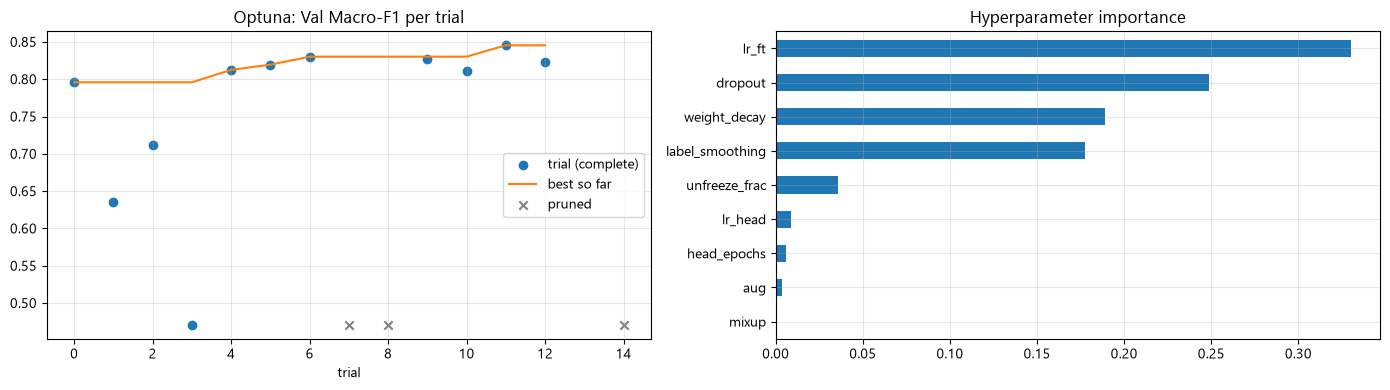

In [18]:
storage = f"sqlite:///{(RESULTS_DIR / 'optuna.db').as_posix()}"
# ss2 = search space ที่มี texture (ชื่อ study ใหม่ เพราะตัวเลือกของ aug เปลี่ยน)
study = optuna.create_study(study_name=f"top1_{TOP1}_{TOP1_ROUND}_ss2", storage=storage, direction="maximize",
                            load_if_exists=True,
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=3))
assert study.direction == optuna.study.StudyDirection.MAXIMIZE and (RESULTS_DIR / "optuna.db").exists(), \
    "study ต้อง maximize Val Macro-F1 และบันทึกลง results/optuna.db"
study.sampler = make_sampler(len(study.trials), SEED)  # รันต่อแล้วไม่สุ่มค่าซ้ำกับ trial เดิม


def objective(trial):
    params = suggest_params(trial)
    try:
        rid = train_one(TOP1, params, SEED, TRIAL_EPOCHS, "trial", trial=trial)
    finally:  # trial ที่ถูก prune/ล้ม ต้องคืนหน่วยความจำ GPU ก่อน trial ถัดไป
        import gc
        gc.collect()
        torch.cuda.empty_cache()
    trial.set_user_attr("run_id", rid)
    return load_run(rid)["val_metrics"]["macro_f1"]


n_stale = fail_stale_trials(study)  # trial ที่ค้างจากการหยุดกลางทาง
if n_stale:
    print(f"ปิด trial ที่ค้างอยู่ {n_stale} trial เป็น FAIL")
n_left = remaining_trials(study, N_TRIALS)
print(f"Optuna: มี {len(study.trials)} trial แล้ว จะรันเพิ่ม {n_left} trial")
if n_left:
    study.optimize(objective, n_trials=n_left, catch=(Exception,), gc_after_trial=True)

trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "duration", "user_attrs"))
trials["duration_min"] = trials.pop("duration").dt.total_seconds() / 60
trials.to_csv(RESULTS_DIR / "optuna_trials.csv", index=False)
complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
if not complete:
    raise RuntimeError("ไม่มี trial ที่สำเร็จเลย ดูข้อความ error ด้านบน")
try:
    imp = optuna.importance.get_param_importances(study)
except Exception as e:  # trial สำเร็จน้อยเกินไป
    print("คำนวณ importance ไม่ได้:", e)
    imp = {}
pd.DataFrame({"param": list(imp), "importance": list(imp.values())}).to_csv(RESULTS_DIR / "optuna_importance.csv", index=False)

BEST_PARAMS = {**TOP1_PARAMS, **study.best_params}
print(f"trial ที่ดีที่สุด #{study.best_trial.number}: Val Macro-F1 {study.best_value:.3f}")
display(pd.DataFrame({"ก่อนจูน": TOP1_PARAMS, "หลังจูน": BEST_PARAMS}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
done = trials[trials.state == "COMPLETE"]
axes[0].scatter(done.number, done.value, label="trial (complete)")
axes[0].plot(done.number, done.value.cummax(), color="C1", label="best so far")
pruned = trials[trials.state == "PRUNED"]
axes[0].scatter(pruned.number, [done.value.min()] * len(pruned), marker="x", color="gray", label="pruned")
axes[0].set(title="Optuna: Val Macro-F1 per trial", xlabel="trial")
axes[0].legend()
if imp:
    pd.Series(imp).sort_values().plot.barh(ax=axes[1], title="Hyperparameter importance")
savefig(fig, "optuna_history.png")
plt.show()

## 9. หลังจูน: Top 1 สูตรที่ดีที่สุด 3 seed

ใช้ hyperparameter จาก trial ที่ดีที่สุด เทรนเต็ม `MAX_EPOCHS` epoch ด้วย seed ชุดเดียวกับ "ก่อนจูน"

เทรน ResNet50 | after | seed 42 | run a50944770df9


  epoch  1 [head    ] loss 1.218 | val acc 0.549 F1 0.504  * | 24s


  epoch  2 [head    ] loss 1.069 | val acc 0.589 F1 0.558  * | 36s


  epoch  3 [head    ] loss 0.997 | val acc 0.610 F1 0.586  * | 48s


  epoch  4 [head    ] loss 0.947 | val acc 0.610 F1 0.579 | 60s


  epoch  5 [head    ] loss 0.915 | val acc 0.626 F1 0.599  * | 72s


... (75 outputs left out)

  epoch 21 [finetune] loss 0.401 | val acc 0.847 F1 0.832 | 422s


  epoch 22 [finetune] loss 0.400 | val acc 0.850 F1 0.835 | 443s
  early stopping (Val Macro-F1 ไม่ดีขึ้น 7 epoch)


-> Val Macro-F1 0.837 | Acc 0.856 | 7.4 นาที


,ก่อนจูน,หลังจูน
Val Macro-F1,0.797 ± 0.006,0.832 ± 0.003
Val Accuracy,0.814 ± 0.006,0.849 ± 0.006


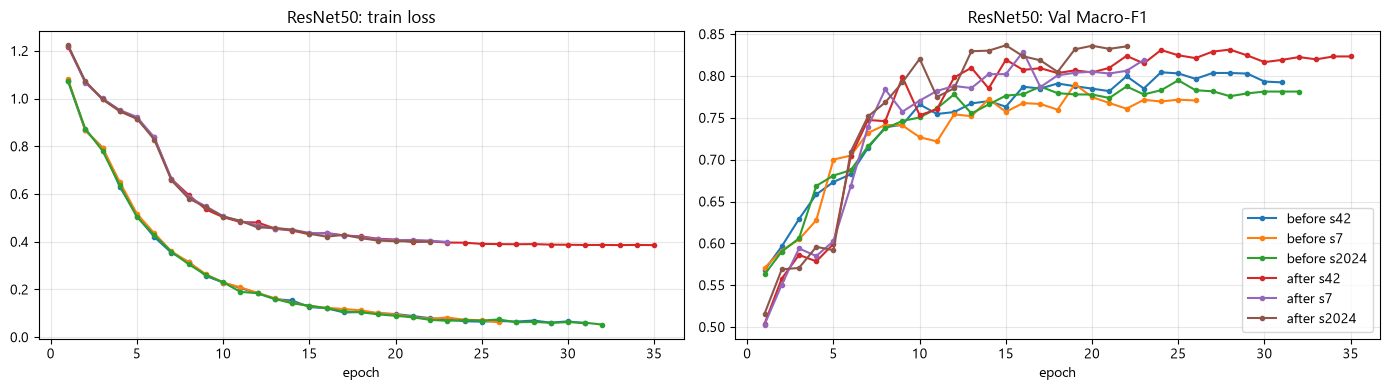

In [19]:
AFTER_RUNS = [train_one(TOP1, BEST_PARAMS, s, MAX_EPOCHS, "after") for s in SEEDS]
after_val = pd.DataFrame([{"seed": s, **load_run(r)["val_metrics"]} for s, r in zip(SEEDS, AFTER_RUNS)]).set_index("seed")
cmp = pd.DataFrame({v: {"Val Macro-F1": f"{d.macro_f1.mean():.3f} ± {d.macro_f1.std(ddof=0):.3f}",
                        "Val Accuracy": f"{d.accuracy.mean():.3f} ± {d.accuracy.std(ddof=0):.3f}"}
                    for v, d in (("ก่อนจูน", before_val), ("หลังจูน", after_val))})
display(cmp)
plot_history({f"before s{s}": r for s, r in zip(SEEDS, BEFORE_RUNS)} | {f"after s{s}": r for s, r in zip(SEEDS, AFTER_RUNS)},
             f"{TOP1_NAME}", "before_after_curves.png")

## 10. ประเมินบนชุด Test: ก่อน vs หลังจูน (ครั้งเดียว)

ชุด Test ถูกใช้ครั้งแรกที่นี่ หลังจากเลือกโมเดลและจูนเสร็จแล้ว รายงาน
- Macro-F1 / Accuracy แบบ mean ± std ของ 3 seed
- รายคลาส, แยกแหล่งข้อมูล, confusion matrix (ใช้ seed ที่ Val Macro-F1 สูงสุดเป็นตัวแทนของแต่ละฝั่ง)
- ช่วงความเชื่อมั่น 95% (bootstrap 1,000 รอบ) และ McNemar test ระหว่างก่อนกับหลังจูน (p < 0.05 = ต่างกันจริง)

ถ้า Test Macro-F1 เฉลี่ยของ "หลังจูน" ต่ำกว่า `F1_TARGET` (0.85) ต้องทำ**ขั้นสำรอง**: เทรน ConvNeXt V2-Tiny (timm) ด้วย flow เดียวกัน
(การตัดสินใจนี้ดูผล Test จึงบันทึกไว้ใน `selection.json` อย่างชัดเจน)

val_macro_f1        test_accuracy        test_macro_f1         \
                mean    std          mean    std          mean    std   
variant                                                                 
before         0.797  0.007         0.814  0.008         0.803  0.005   
after          0.832  0.004         0.817  0.014         0.804  0.014   

        test_min_recall         
                   mean    std  
variant                         
before            0.702  0.014  
after             0.722  0.030

,variant,source,n,accuracy,macro_f1,min_recall
0,before,iBUG,133,0.910,0.815,0.800
1,before,TextileClass7,195,0.764,0.764,0.608
2,after,iBUG,133,0.902,0.832,0.800
3,after,TextileClass7,195,0.738,0.739,0.608


,variant,seed,test_macro_f1,ci95_low,ci95_high,mcnemar_after_right_before_wrong,mcnemar_before_right_after_wrong,mcnemar_p
0,before,42,0.8093,0.7629,0.8522,20,26,0.4614
1,after,2024,0.7910,0.7441,0.8358,20,26,0.4614


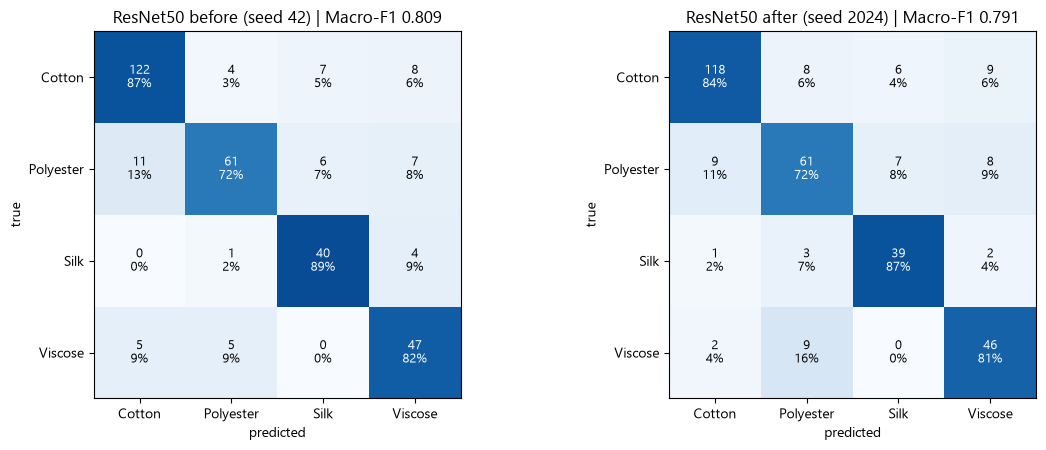

,เป้า,ผล,ผ่าน
ตัวชี้วัด,,,
"Macro-F1 (Test, mean 3 seed)",≥ 0.85,0.804,False
"Accuracy (Test, mean 3 seed)",≥ 85%,0.817,False
Recall ต่ำสุดรายคลาส (Test),≥ 0.75,0.718,False


⚠️ Test Macro-F1 หลังจูน 0.804 < 0.85: ต้องทำขั้นสำรอง (ConvNeXt V2-Tiny จาก timm)


round,none,v1,v2,texture
model,,,,
ConvNeXt-Tiny,0.780,0.694,0.582,0.747
DenseNet121,0.693,0.529,0.469,0.698
EfficientNet-B0,0.714,0.629,0.577,0.702
ResNet50,0.766,0.670,0.645,0.809


In [20]:
VARIANTS = {"before": BEFORE_RUNS, "after": AFTER_RUNS}
rows, TEST_PROBA = [], {}
for v, runs in VARIANTS.items():
    for s, rid in zip(SEEDS, runs):
        TEST_PROBA[(v, s)] = predict_split(rid, "test")
        tm = evaluate(y_te, TEST_PROBA[(v, s)])
        rows.append({"variant": v, "seed": s, "run_id": rid, "val_macro_f1": load_run(rid)["val_metrics"]["macro_f1"],
                     "val_accuracy": load_run(rid)["val_metrics"]["accuracy"],
                     "test_accuracy": tm["accuracy"], "test_macro_f1": tm["macro_f1"], "test_min_recall": tm["min_recall"]})
tba = pd.DataFrame(rows)
tba.to_csv(RESULTS_DIR / "test_before_after.csv", index=False)
summary = tba.groupby("variant")[["val_macro_f1", "test_accuracy", "test_macro_f1", "test_min_recall"]].agg(["mean", "std"])
display(summary.loc[["before", "after"]].round(3))

# ตัวแทนของแต่ละฝั่ง = seed ที่ Val Macro-F1 สูงสุด (เลือกจาก Val ไม่ใช่ Test)
REP = {v: tba[tba.variant == v].sort_values("val_macro_f1", ascending=False).iloc[0] for v in VARIANTS}
REP_PROBA = {v: TEST_PROBA[(v, int(REP[v].seed))] for v in VARIANTS}
REP_METRICS = {v: evaluate(y_te, REP_PROBA[v]) for v in VARIANTS}

pd.DataFrame([{"variant": v, "class": c, "precision": m[f"precision_{c}"], "recall": m[f"recall_{c}"], "f1": m[f"f1_{c}"]}
              for v, m in REP_METRICS.items() for c in CLASSES]).to_csv(RESULTS_DIR / "per_class_test.csv", index=False)

src_te = split_df["source"][masks["test"]].to_numpy()
per_source = pd.DataFrame([{"variant": v, "source": s, "n": int((src_te == s).sum()),
                            **{k: val for k, val in evaluate(y_te[src_te == s], REP_PROBA[v][src_te == s]).items()
                               if k in ("accuracy", "macro_f1", "min_recall")}}
                           for v in VARIANTS for s in SOURCES if (src_te == s).any()])
per_source.to_csv(RESULTS_DIR / "per_source_test.csv", index=False)
display(per_source.round(3))

pred = {v: p.argmax(1) for v, p in REP_PROBA.items()}
b, c, p_mc = mcnemar(y_te, pred["after"], pred["before"])
sig = pd.DataFrame([{"variant": v, "seed": int(REP[v].seed), "test_macro_f1": REP_METRICS[v]["macro_f1"],
                     **dict(zip(("ci95_low", "ci95_high"), bootstrap_ci(y_te, pred[v], seed=SEED)))} for v in VARIANTS])
sig["mcnemar_after_right_before_wrong"], sig["mcnemar_before_right_after_wrong"], sig["mcnemar_p"] = b, c, p_mc
sig.to_csv(RESULTS_DIR / "significance.csv", index=False)
display(sig.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, v in zip(axes, VARIANTS):
    cm = confusion_matrix(y_te, pred[v], labels=range(len(CLASSES)))
    (RESULTS_DIR / f"confusion_{v}.json").write_text(json.dumps({"classes": CLASSES, "matrix": cm.tolist()}), encoding="utf-8")
    plot_cm(ax, cm)
    ax.set(title=f"{TOP1_NAME} {v} (seed {int(REP[v].seed)}) | Macro-F1 {REP_METRICS[v]['macro_f1']:.3f}",
           xlabel="predicted", ylabel="true")
savefig(fig, "confusion_before_after.png")
plt.show()

after_mean = tba[tba.variant == "after"].test_macro_f1.mean()
am = REP_METRICS["after"]
targets = pd.DataFrame([
    ("Macro-F1 (Test, mean 3 seed)", f"≥ {F1_TARGET}", after_mean, after_mean >= F1_TARGET),
    ("Accuracy (Test, mean 3 seed)", "≥ 85%", tba[tba.variant == "after"].test_accuracy.mean(),
     tba[tba.variant == "after"].test_accuracy.mean() >= 0.85),
    ("Recall ต่ำสุดรายคลาส (Test)", "≥ 0.75", am["min_recall"], am["min_recall"] >= 0.75),
], columns=["ตัวชี้วัด", "เป้า", "ผล", "ผ่าน"]).set_index("ตัวชี้วัด")
display(targets.round(3))

FALLBACK_NEEDED = bool(after_mean < F1_TARGET)
selection["fallback"] = {"needed": FALLBACK_NEEDED, "after_test_macro_f1_mean": float(after_mean), "target": F1_TARGET,
                         "note": "decision looks at Test (the only use of Test before the final report)"}
(RESULTS_DIR / "selection.json").write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding="utf-8")
if FALLBACK_NEEDED:
    print(f"⚠️ Test Macro-F1 หลังจูน {after_mean:.3f} < {F1_TARGET}: ต้องทำขั้นสำรอง (ConvNeXt V2-Tiny จาก timm)")
else:
    print(f"ผ่านเป้า: Test Macro-F1 หลังจูน {after_mean:.3f} ≥ {F1_TARGET}")

# ผล Test ของทั้ง 16 run ในรอบคัดเลือก: รายงานหลังเลือกโมเดลแล้ว (ไม่ได้ใช้เลือก)
screening_test = pd.DataFrame([{"model": fl.TV_ZOO[a]["name"], "round": r, "candidate": f"{a}|{r}",
                                **{f"test_{k}": v for k, v in evaluate(y_te, predict_split(rid, "test")).items()
                                   if k in ("accuracy", "macro_precision", "macro_recall", "macro_f1", "min_recall")}}
                               for (a, r), rid in SCREEN_RUNS.items()])
screening_test.to_csv(RESULTS_DIR / "screening_test.csv", index=False)
display(screening_test.pivot(index="model", columns="round", values="test_macro_f1")[ROUNDS].round(3))

## 10b. Generalization: Train vs Val vs Test vs Unseen (ตามสไลด์)

สำหรับทั้ง 16 run ในรอบคัดเลือกและตัวแทนก่อน/หลังจูน วัด Accuracy / Precision / Recall / F1 / Loss บนทุกชุด
(Train วัดใน eval mode ไม่มี augmentation) แล้ววาดกราฟแบบสไลด์ต่อ run:
1. แท่ง Train vs Val vs Test (vs Unseen ถ้ามี) 2. learning curve loss และ accuracy พร้อมข้อความวินิจฉัย overfitting 3. confusion matrix (นับจำนวน) บน Test

ช่องว่างระหว่าง Train กับ Val/Test ที่กว้าง = overfitting ส่วน Unseen ที่ต่ำกว่า Test มาก = โมเดลยังใช้กับรูปต่างแหล่งไม่ได้ดี

Unseen: 382 รูป {'Cotton': 100, 'Polyester': 100, 'Silk': 100, 'Viscose': 82}


generalization:   0%|          | 0/18 [00:00<?, ?it/s]

split,test,train,unseen,val
run,,,,
ConvNeXt-Tiny | none,0.780,0.998,0.290,0.790
ConvNeXt-Tiny | texture,0.747,0.960,0.302,0.790
ConvNeXt-Tiny | v1,0.694,0.858,0.318,0.690
ConvNeXt-Tiny | v2,0.582,0.729,0.296,0.624
DenseNet121 | none,0.693,0.979,0.286,0.768
DenseNet121 | texture,0.698,0.907,0.289,0.752
DenseNet121 | v1,0.529,0.613,0.274,0.570
DenseNet121 | v2,0.469,0.555,0.243,0.514
EfficientNet-B0 | none,0.714,0.957,0.185,0.740


บันทึกกราฟต่อ run ไว้ที่ C:\Users\Natth\OneDrive\Desktop\ml\results\gen_*.png


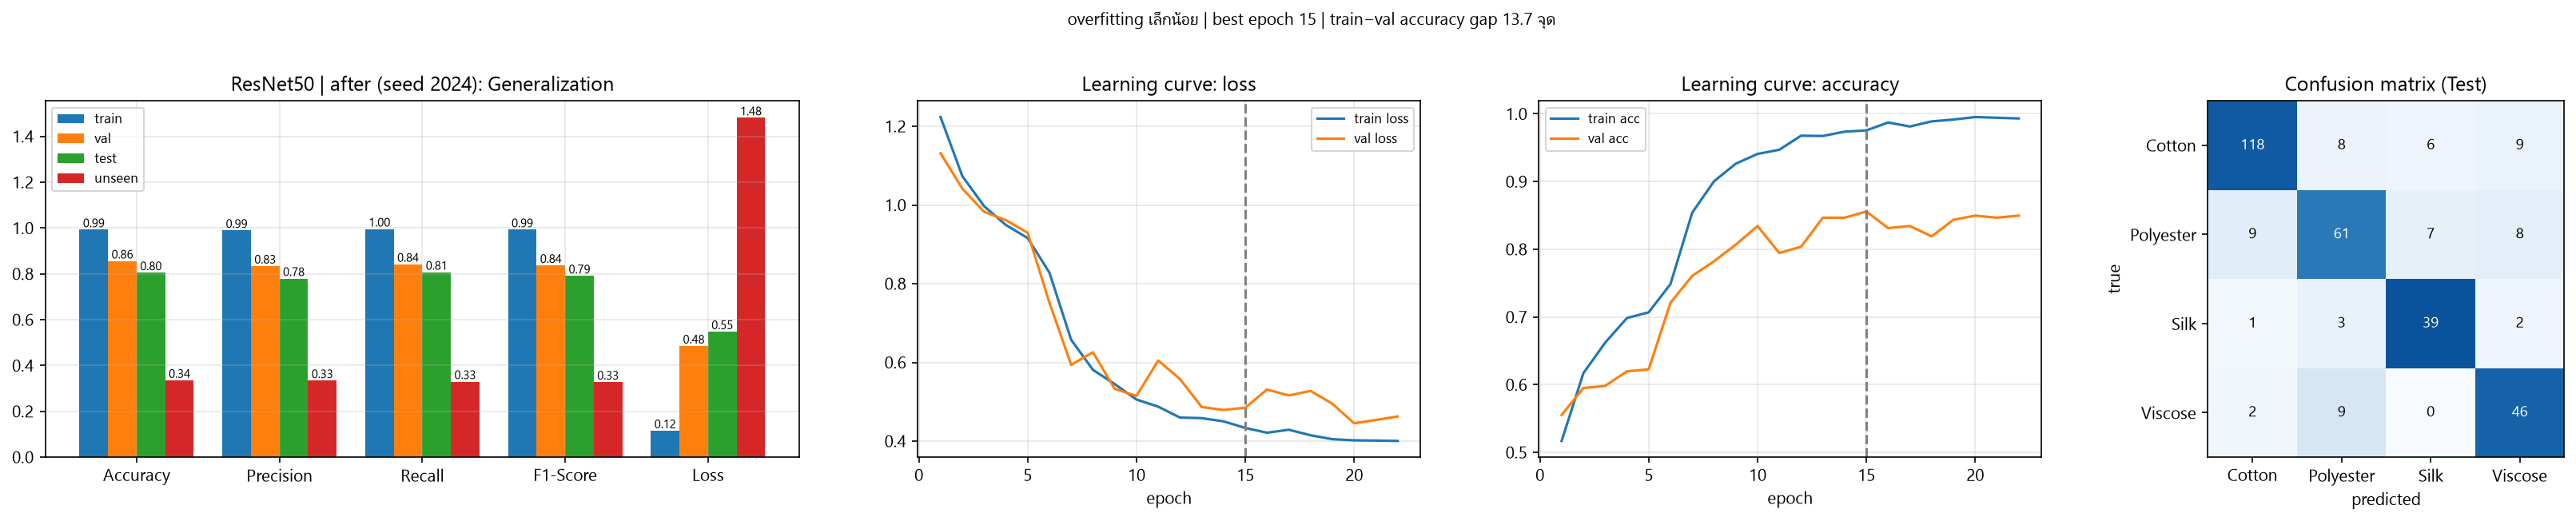

In [21]:
unseen_df = None
if (UNSEEN_DIR / "sources.csv").exists():
    unseen_df = pd.read_csv(UNSEEN_DIR / "sources.csv")
    unseen_df = unseen_df[unseen_df["class"].isin(CLASSES)].reset_index(drop=True)
    y_un = unseen_df["class"].map(CLASS_TO_IDX).to_numpy()
    print(f"Unseen: {len(unseen_df)} รูป", unseen_df["class"].value_counts().reindex(CLASSES).to_dict())
else:
    print(f"ยังไม่มี {UNSEEN_DIR / 'sources.csv'}: ข้ามส่วน Unseen (สร้างชุด unseen_data แล้วรันส่วน 10b–10c ใหม่)")


def predict_paths(run_id, paths, bs=64):
    ds = fl.FabricDataset(paths, np.zeros(len(paths), dtype=int), train=False)
    loader = torch.utils.data.DataLoader(ds, batch_size=bs, num_workers=NUM_WORKERS)
    return predict_model(load_model(run_id), loader)


def split_metrics(run_id):
    out = {}
    for name, y in (("train", y_tr), ("val", y_va), ("test", y_te)):
        pr = predict_split(run_id, name)
        out[name] = {**evaluate(y, pr), "loss": ce_loss(y, pr)}
    if unseen_df is not None:
        pr = predict_paths(run_id, [UNSEEN_DIR / f for f in unseen_df.file])
        _PROBA_CACHE[(run_id, "unseen")] = pr
        out["unseen"] = {**evaluate(y_un, pr), "loss": ce_loss(y_un, pr)}
    return out


GEN_RUNS = {f"{fl.TV_ZOO[a]['name']} | {r}": rid for (a, r), rid in SCREEN_RUNS.items()}
GEN_RUNS |= {f"{TOP1_NAME} | before (seed {int(REP['before'].seed)})": REP["before"].run_id,
             f"{TOP1_NAME} | after (seed {int(REP['after'].seed)})": REP["after"].run_id}
gen_rows = []
for label, rid in tqdm(GEN_RUNS.items(), desc="generalization"):
    for split, m in split_metrics(rid).items():
        gen_rows.append({"run": label, "run_id": rid, "split": split,
                         **{k: m[k] for k in ("accuracy", "macro_precision", "macro_recall", "macro_f1", "loss")}})
generalization = pd.DataFrame(gen_rows)
generalization.to_csv(RESULTS_DIR / "generalization.csv", index=False)
display(generalization.pivot(index="run", columns="split", values="macro_f1").round(3))

METRICS = [("accuracy", "Accuracy"), ("macro_precision", "Precision"), ("macro_recall", "Recall"),
           ("macro_f1", "F1-Score"), ("loss", "Loss")]
for label, rid in GEN_RUNS.items():
    g = generalization[generalization.run == label].set_index("split")
    h = pd.DataFrame(load_run(rid)["history"])
    slug = re.sub(r"[^0-9A-Za-z]+", "_", label).strip("_")
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.2), gridspec_kw={"width_ratios": [1.5, 1, 1, 0.9]})
    for k, split in enumerate(g.index):
        bars = axes[0].bar(np.arange(len(METRICS)) + (k - (len(g) - 1) / 2) * 0.2, [g.loc[split, m] for m, _ in METRICS],
                           width=0.2, label=split)
        axes[0].bar_label(bars, fmt="%.2f", fontsize=7)
    axes[0].set(xticks=range(len(METRICS)), xticklabels=[t for _, t in METRICS], title=f"{label}: Generalization")
    axes[0].legend(fontsize=8)
    axes[1].plot(h.epoch, h.train_loss, label="train loss")
    axes[1].plot(h.epoch, h.val_loss, label="val loss")
    axes[1].set(title="Learning curve: loss", xlabel="epoch")
    axes[1].legend(fontsize=8)
    axes[2].plot(h.epoch, h.train_accuracy, label="train acc")
    axes[2].plot(h.epoch, h.val_accuracy, label="val acc")
    best = int(h.loc[h.val_macro_f1.idxmax(), "epoch"])
    for ax in axes[1:3]:
        ax.axvline(best, color="gray", ls="--")
    axes[2].set(title="Learning curve: accuracy", xlabel="epoch")
    axes[2].legend(fontsize=8)
    plot_cm(axes[3], confusion_matrix(y_te, predict_split(rid, "test").argmax(1), labels=range(len(CLASSES))), counts_only=True)
    axes[3].set_title("Confusion matrix (Test)")
    fig.suptitle(diagnose_fit(load_run(rid)["history"], g.loc["train", "accuracy"]), y=1.02, fontsize=10)
    savefig(fig, f"gen_{slug}.png")
    plt.close(fig)
print("บันทึกกราฟต่อ run ไว้ที่", RESULTS_DIR / "gen_*.png")
display(Image.open(RESULTS_DIR / f"gen_{re.sub(r'[^0-9A-Za-z]+', '_', list(GEN_RUNS)[-1]).strip('_')}.png"))

## 10c. Unseen data (รูปจากอินเทอร์เน็ต)

รูปผ้าจาก **TextileNet** (Zhong et al., 2023) คลาสละราว 100 รูป เป็นรูปสินค้าจากเว็บ ต่างจากรูปที่ใช้เทรน
คัดกรองโดย AI (ตัดภาพตัดต่อ ภาพที่คนเป็นจุดหลัก และรูปที่ขัดกับ label อย่างชัดเจน) ส่วน label มาจาก TextileNet
ใช้วัดผลอย่างเดียว ไม่ได้ใช้เทรนหรือเลือกโมเดล รัน cell 10b–10c ซ้ำได้หลังเพิ่ม/แก้ `unseen_data/`

,precision,recall,f1
Cotton,0.405,0.32,0.358
Polyester,0.326,0.45,0.378
Silk,0.347,0.33,0.338
Viscose,0.257,0.22,0.237


ResNet50 หลังจูน บน Unseen: Accuracy 0.335, Macro-F1 0.328 (เทียบ Test 0.791)


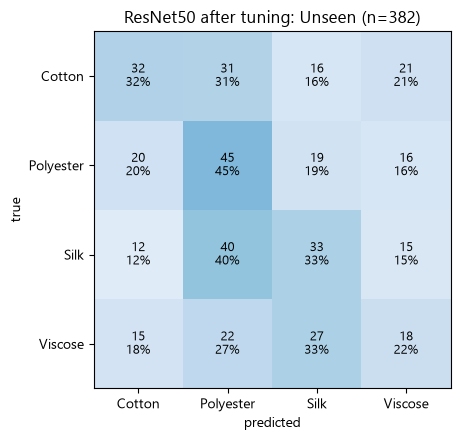

In [22]:
if unseen_df is None:
    print("ยังไม่มีชุด Unseen: ข้าม")
else:
    rid = REP["after"].run_id
    pr = _PROBA_CACHE.get((rid, "unseen"))
    if pr is None:
        pr = predict_paths(rid, [UNSEEN_DIR / f for f in unseen_df.file])
    pred_u = pr.argmax(1)
    up = unseen_df[["file", "class"]].assign(pred=[CLASSES[i] for i in pred_u], conf=pr.max(1),
                                             **{f"p_{c}": pr[:, i] for i, c in enumerate(CLASSES)})
    up.to_csv(RESULTS_DIR / "unseen_predictions.csv", index=False)
    um = generalization[generalization.split == "unseen"][["run", "accuracy", "macro_precision", "macro_recall", "macro_f1", "loss"]]
    um.to_csv(RESULTS_DIR / "unseen_metrics.csv", index=False)
    m = evaluate(y_un, pr)
    display(pd.DataFrame({c: {"precision": m[f"precision_{c}"], "recall": m[f"recall_{c}"], "f1": m[f"f1_{c}"]}
                          for c in CLASSES}).T.round(3))
    print(f"{TOP1_NAME} หลังจูน บน Unseen: Accuracy {m['accuracy']:.3f}, Macro-F1 {m['macro_f1']:.3f} "
          f"(เทียบ Test {REP_METRICS['after']['macro_f1']:.3f})")
    fig, ax = plt.subplots(figsize=(5, 4.5))
    plot_cm(ax, confusion_matrix(y_un, pred_u, labels=range(len(CLASSES))))
    ax.set_title(f"{TOP1_NAME} after tuning: Unseen (n={len(y_un)})")
    savefig(fig, "unseen_confusion.png")
    plt.show()

## 11. Error analysis

รูปใน Test ที่โมเดลหลังจูนทายผิดโดยมั่นใจสูงสุด 12 รูป และคู่คลาสที่สับสนบ่อย (R3 พบว่าคู่ Cotton–Polyester สับสนกันบ่อยเพราะลายผิวคล้ายกัน)

In [23]:
test_df = split_df[masks["test"]].reset_index(drop=True)
proba = REP_PROBA["after"]
pred_a, conf = proba.argmax(1), proba.max(1)
wrong = np.flatnonzero(pred_a != y_te)
top_wrong = wrong[np.argsort(-conf[wrong])][:12]
print(f"{TOP1_NAME} หลังจูน: ทายผิด {len(wrong)} จาก {len(y_te)} รูปใน Test")
if len(top_wrong):
    ncol = 4
    nrow = int(np.ceil(len(top_wrong) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.4 * nrow), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), top_wrong):
        img = fl.load_pil(DATA_DIR / test_df.path[i])
        img.thumbnail((256, 256))
        ax.imshow(img)
        ax.set_title(f"true {CLASSES[y_te[i]]} -> {CLASSES[pred_a[i]]}\nconf {conf[i]:.0%} | {test_df.source[i]}", fontsize=9)
    fig.suptitle(f"{TOP1_NAME} (after tuning): most confident mistakes (test)")
    savefig(fig, "error_top_confident_mistakes.png")
    plt.show()
cm = confusion_matrix(y_te, pred_a, labels=range(len(CLASSES)))
pairs = pd.DataFrame([{"true": CLASSES[i], "predicted": CLASSES[j], "count": int(cm[i, j]),
                       "% of true class": cm[i, j] / max(cm[i].sum(), 1)}
                      for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0])
if len(pairs):
    display(pairs.sort_values("count", ascending=False).head(6).style.format({"% of true class": "{:.1%}"}))

## 12. Export

บันทึก run "หลังจูน" ที่ Val Macro-F1 สูงสุดเป็น `models/best_model.pth` พร้อม `models/model_meta.json`
แล้วตรวจว่าโหลดผ่าน `fl.load_predictor` (ทางเดียวกับแอป) ได้ผลตรงกับใน notebook

In [24]:
rid = REP["after"].run_id
shutil.copyfile(RUNS_DIR / f"{rid}.pth", MODELS_DIR / "best_model.pth")
r = load_run(rid)
summ = {v: {"test_macro_f1_mean": float(tba[tba.variant == v].test_macro_f1.mean()),
            "test_macro_f1_std": float(tba[tba.variant == v].test_macro_f1.std(ddof=0)),
            "test_accuracy_mean": float(tba[tba.variant == v].test_accuracy.mean())} for v in VARIANTS}
meta = {"framework": "torch", "model_file": "best_model.pth", "arch": TOP1, "round": TOP1_ROUND,
        "model_name": f"{TOP1_NAME} (รอบ {TOP1_ROUND}, fine-tuned + Optuna)", "classes": CLASSES,
        "img_size": IMG_SIZE, "preprocessing": "RGB, EXIF-rotated, resize shorter side to 256, center crop 224, ImageNet mean/std",
        "params": r["params"], "seed": int(REP["after"].seed), "run_id": rid,
        "val_metrics": r["val_metrics"], "test_metrics": REP_METRICS["after"], "test_before_after": summ,
        "conf_threshold": CONF_THRESHOLD, "infer_ms_per_img": time_inference(rid),
        "fallback_needed": FALLBACK_NEEDED, "n_images": dict(zip(("train", "val", "test"), N_IMAGES)),
        "data_fingerprint": FINGERPRINT, "exported_at": time.strftime("%Y-%m-%d %H:%M:%S")}
(MODELS_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

# ตรวจว่าโหลดแบบเดียวกับแอปแล้วได้ผลตรงกับ notebook (fp16 + batch ต่างกันทำให้ต่างได้เล็กน้อย)
app_pred = fl.load_predictor(MODELS_DIR, DEVICE)
chk = [DATA_DIR / p for p in split_df["path"][masks["val"]].iloc[:20]]
p_app, p_nb = app_pred.predict_proba(chk), predict_split(rid, "val")[:20]
ok, msg = check_export(p_app, p_nb)
assert ok, f"ผลจาก load_predictor ไม่ตรงกับ notebook: {msg}"
print(f"Export {TOP1_NAME} (seed {meta['seed']}) -> {MODELS_DIR / 'best_model.pth'}; load_predictor ตรงกับ notebook ({msg})")
del app_pred

Export ResNet50 (seed 2024) -> C:\Users\Natth\OneDrive\Desktop\ml\models\best_model.pth; load_predictor ตรงกับ notebook (max diff 3.8e-04, argmax ต่างกัน 0/20 รูป)


## 13. เขียนแอป Streamlit (`app.py`)

แอป 4 หน้า: **เปรียบเทียบ 4 โมเดล × 3 รอบ (16 run)**, **ก่อน vs หลังจูน**, **ทำนายรูป** และ **Unseen data** อ่านเฉพาะไฟล์ใน `results/` และ `models/` ที่ notebook สร้าง
ถ้ายังไม่มีไฟล์ของหน้าใด หน้านั้นจะบอกว่าต้องรัน notebook ส่วนไหน รันเองได้ด้วย `streamlit run app.py`

In [25]:
%%writefile app.py
"""FabricSort: แอป Streamlit 4 หน้า (เปรียบเทียบ 4 โมเดล / ก่อน vs หลังจูน / ทำนายรูป / Unseen)

สร้างจาก fabric_classification.ipynb (ส่วนที่ 13) รันด้วย: streamlit run app.py
อ่านเฉพาะไฟล์ใน results/ และ models/ ที่ notebook สร้าง ไม่คำนวณผลใหม่
"""
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

ROOT = Path(os.environ.get("FABRIC_APP_ROOT") or Path(__file__).resolve().parent)
RES, MOD = ROOT / "results", ROOT / "models"
CLASSES = ["Cotton", "Polyester", "Silk", "Viscose"]
VARIANT_TH = {"before": "ก่อนจูน", "after": "หลังจูน"}
ROUNDS = ["none", "v1", "v2", "texture"]
UNS = ROOT / "unseen_data"
TH_NAME = {"Cotton": "ผ้าฝ้าย", "Polyester": "โพลีเอสเตอร์", "Silk": "ผ้าไหม", "Viscose": "วิสคอส (เรยอน)"}
ADVICE = {
    "Cotton": "เส้นใยธรรมชาติ (เซลลูโลส) รีไซเคิลเชิงกลได้ดี: ตัด/ฉีกเป็นเส้นใยแล้วปั่นเป็นด้ายใหม่ "
              "หรือทำเป็นวัสดุบุ ฉนวน และผ้าเช็ด ควรแยกตามสีเพื่อลดการฟอกย้อมซ้ำ",
    "Polyester": "พลาสติกชนิด PET: รีไซเคิลเชิงกลโดยหลอมเป็นเม็ดแล้วรีดเป็นเส้นใยใหม่ "
                 "หรือรีไซเคิลเชิงเคมี (depolymerization) ย่อยกลับเป็นโมโนเมอร์เพื่อผลิตโพลีเอสเตอร์คุณภาพเท่าเดิม",
    "Silk": "เส้นใยโปรตีนมูลค่าสูง: เหมาะกับการนำกลับมาใช้ใหม่หรือ upcycling "
            "หรือรีไซเคิลเชิงกลเป็นเส้นใยสั้นสำหรับผ้าผสม ไม่ควรปนกับผ้าใยสังเคราะห์",
    "Viscose": "เซลลูโลสที่ผ่านกระบวนการทางเคมี (regenerated cellulose): เส้นใยสั้นและอ่อนลงเมื่อรีไซเคิลเชิงกล "
               "จึงเหมาะกับรีไซเคิลเชิงเคมี คือละลายเป็นเยื่อเซลลูโลสแล้วผลิตเส้นใยใหม่ (เช่น lyocell)",
}
METRIC_TH = {"val_accuracy": "Accuracy", "val_macro_precision": "Precision", "val_macro_recall": "Recall",
             "val_macro_f1": "Macro-F1", "val_min_recall": "Recall ต่ำสุด"}


# ---------- อ่านไฟล์ผล ----------
def need(files, section) -> bool:
    """ถ้าไฟล์ใดยังไม่มี แสดงว่าต้องรัน notebook ส่วนไหน แล้วคืน False"""
    missing = [Path(f).name for f in files if not Path(f).exists()]
    if missing:
        st.info(f"ยังไม่มีผล ({', '.join(missing)}): รัน notebook ส่วนที่ {section} ก่อน แล้วรีเฟรชหน้านี้")
        return False
    return True


@st.cache_data
def _read_csv(path, mtime):
    return pd.read_csv(path)


@st.cache_data
def _read_json(path, mtime):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def csv(path: Path) -> pd.DataFrame:
    return _read_csv(str(path), path.stat().st_mtime)


def js(path: Path) -> dict:
    return _read_json(str(path), path.stat().st_mtime)


def model_meta():
    p = MOD / "model_meta.json"
    return js(p) if p.exists() else None


def sidebar():
    with st.sidebar:
        st.header("ข้อมูลโมเดล")
        meta = model_meta()
        if meta is None:
            st.caption("ยังไม่มีโมเดลที่ export (รัน notebook ส่วนที่ 12)")
        else:
            st.markdown(f"**โมเดล:** {meta['model_name']}")
            tm = meta["test_metrics"]
            c1, c2 = st.columns(2)
            c1.metric("Accuracy (Test)", f"{tm['accuracy']:.1%}")
            c2.metric("Macro-F1 (Test)", f"{tm['macro_f1']:.3f}")
            st.caption(f"ทดสอบกับ {meta['n_images']['test']:,} รูป · export เมื่อ {meta['exported_at']}")
        st.subheader("ข้อจำกัด")
        st.markdown(
            "- จำแนกได้เพียง 4 ชนิด: Cotton, Polyester, Silk, Viscose\n"
            "- ไม่รองรับผ้าผสม (blend) หรือผ้าชนิดอื่น ระบบจะตอบเป็น 1 ใน 4 ชนิดเสมอ\n"
            "- 1 รูปควรมีผ้าชิ้นเดียว ถ่ายใกล้และเต็มเฟรม\n"
            "- เทรนจากชุดข้อมูลสาธารณะ ความแม่นยำกับรูปจากโรงงานจริงอาจต่ำกว่านี้\n"
            "- ความมั่นใจต่ำ ควรให้คนตรวจซ้ำ\n"
            "- รูปประมวลผลในเครื่องนี้เท่านั้น ไม่ถูกบันทึกหรือส่งออกไปที่อื่น"
        )


# ---------- หน้า 1: เปรียบเทียบ 4 โมเดล ----------
def page_compare():
    st.title("เปรียบเทียบ 4 โมเดล × 4 รอบ")
    st.caption("none = ไม่ทำ augmentation, v1 = แบบเบา, v2 = แบบหนัก (ตามสไลด์), texture = แบบรักษาพื้นผิวผ้า · "
               "สูตร default เดียวกัน (seed 42) · "
               "เลือก Top 1 จากชุด Validation")
    if not need([RES / "screening.csv", RES / "selection.json"], "5–6"):
        return
    df, sel = csv(RES / "screening.csv"), js(RES / "selection.json")
    df["run"] = df.model + " | " + df["round"]
    top = df[df.candidate == sel["top1_candidate"]].iloc[0]
    st.success(f"🏆 Top 1: **{sel['top1_name']} รอบ {sel['top1_round']}**")
    meta = model_meta()
    if meta and meta.get("arch") != sel.get("top1_arch"):
        st.caption(f"ขั้นนี้คือรอบคัดเลือกด้วยสูตรเริ่มต้น · หลังจูนครบ 4 โมเดล แอปเปลี่ยนไปใช้ **{meta['model_name']}** "
                   "(ดูหน้า ก่อน vs หลังจูน)")
    cols = st.columns(4)
    cols[0].metric("Val Macro-F1", f"{top.val_macro_f1:.3f}")
    cols[1].metric("Val Accuracy", f"{top.val_accuracy:.1%}")
    cols[2].metric("Inference / รูป", f"{top.infer_ms_per_img:.0f} ms")
    cols[3].metric("ขนาดไฟล์", f"{top.size_mb:.0f} MB")

    fig = px.bar(df, x="model", y="val_macro_f1", color="round", barmode="group", text_auto=".3f",
                 category_orders={"round": ROUNDS}, title="Val Macro-F1: โมเดล × รอบ augmentation")
    fig.update_yaxes(range=[0, 1])
    st.plotly_chart(fig, use_container_width=True)

    long = df.melt(id_vars="run", value_vars=list(METRIC_TH), var_name="metric", value_name="value")
    long["metric"] = long["metric"].map(METRIC_TH)
    fig = px.bar(long, x="metric", y="value", color="run", barmode="group", title="ตัวชี้วัดทั้งหมดบน Validation (16 run)")
    fig.update_yaxes(range=[0, 1])
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("ตารางผลทั้ง 16 run")
    show = df[["model", "round", "val_accuracy", "val_macro_precision", "val_macro_recall", "val_macro_f1",
               "val_min_recall", "epochs_trained", "train_time_s", "fit"]]
    if (RES / "screening_test.csv").exists():
        show = show.merge(csv(RES / "screening_test.csv")[["model", "round", "test_accuracy", "test_macro_f1"]],
                          on=["model", "round"], how="left")
        st.caption("คอลัมน์ test_* คือผลบนชุด Test ที่รายงานหลังเลือกโมเดลแล้ว ไม่ได้ใช้ในการเลือก")
    st.dataframe(show.round(3), hide_index=True, use_container_width=True)

    st.subheader("ขนาดโมเดล")
    st.dataframe(df.drop_duplicates("model")[["model", "size_mb", "params_M", "imagenet_top1", "imagenet_top5",
                                              "infer_ms_per_img"]]
                 .rename(columns={"size_mb": "ขนาด (MB)", "params_M": "พารามิเตอร์ (M)", "imagenet_top1": "ImageNet Top-1 (%)",
                                  "imagenet_top5": "ImageNet Top-5 (%)", "infer_ms_per_img": "inference (ms/รูป)"}).round(2),
                 hide_index=True)

    st.subheader("รายละเอียดราย run")
    run = st.selectbox("เลือก run", df.run.tolist(), index=int(np.flatnonzero(df.candidate == sel["top1_candidate"])[0]))
    row = df[df.run == run].iloc[0]
    st.markdown(f"**วินิจฉัย:** {row.fit}")
    gpath = RES / "generalization.csv"
    if gpath.exists():
        g = csv(gpath)
        g = g[g.run_id == row.run_id].drop_duplicates("split")
        if len(g):
            gl = g.melt(id_vars="split", value_vars=["accuracy", "macro_precision", "macro_recall", "macro_f1", "loss"],
                        var_name="metric", value_name="value")
            st.plotly_chart(px.bar(gl, x="metric", y="value", color="split", barmode="group", text_auto=".2f",
                                   title="Generalization: Train vs Val vs Test vs Unseen"), use_container_width=True)
    hpath = RES / "histories" / f"{row.run_id}.json"
    if need([hpath], "5"):
        h = pd.DataFrame(js(hpath)["history"])
        c1, c2 = st.columns(2)
        c1.plotly_chart(px.line(h, x="epoch", y=[c for c in ("train_loss", "val_loss") if c in h], markers=True,
                                title="Learning curve: loss"), use_container_width=True)
        c2.plotly_chart(px.line(h, x="epoch", y=[c for c in ("train_accuracy", "val_accuracy") if c in h], markers=True,
                                title="Learning curve: accuracy"), use_container_width=True)
    rec = df[df.run == run].melt(value_vars=[f"recall_{c}" for c in CLASSES], var_name="class", value_name="recall")
    rec["class"] = rec["class"].str.replace("recall_", "")
    fig = px.bar(rec, x="class", y="recall", text_auto=".2f", title=f"Recall รายคลาส (Val): {run}")
    fig.update_yaxes(range=[0, 1])
    st.plotly_chart(fig, use_container_width=True)
    st.markdown(f"**เกณฑ์เลือก:** Val Macro-F1 สูงสุด ถ้าต่างกันไม่เกิน 0.01 เลือกตัวที่ inference เร็วกว่า · "
                f"กลุ่มที่ต่างไม่เกิน 0.01: {', '.join(sel['candidates_within_0.01'])}")


# ---------- หน้า 2: ก่อน vs หลังจูน ----------
OTH = RES / "others"
OPTUNA_FILES = {"resnet50": RES / "optuna_trials.csv"}  # ตัวอื่นอยู่ที่ others/optuna_trials_<arch>.csv


def cm_figure(matrix, classes, title, scale="Blues"):
    m = np.array(matrix)
    norm = m / np.clip(m.sum(1, keepdims=True), 1, None)
    fig = px.imshow(norm, x=classes, y=classes, zmin=0, zmax=1, color_continuous_scale=scale,
                    labels={"x": "ทาย", "y": "จริง", "color": "สัดส่วน"}, title=title)
    fig.update_traces(text=m, texttemplate="%{text}<br>%{z:.0%}")
    return fig


def optuna_figure(tr, title):
    done = tr[tr.state == "COMPLETE"].sort_values("number")
    fig = go.Figure()
    fig.add_scatter(x=done.number, y=done.value, mode="markers", name="trial")
    fig.add_scatter(x=done.number, y=done.value.cummax(), mode="lines", name="ดีที่สุดถึงตอนนั้น")
    pruned = tr[tr.state == "PRUNED"]
    if len(pruned) and len(done):
        fig.add_scatter(x=pruned.number, y=[done.value.min()] * len(pruned), mode="markers", name="ถูกตัด (pruned)",
                        marker_symbol="x", marker_color="gray")
    fig.update_layout(title=title, xaxis_title="trial")
    return fig


def tuning_all_models():
    """ก่อน/หลังจูนครบ 4 โมเดล (results/others/ จาก tune_others.ipynb + tools/plot_before_after_4models.py)"""
    summ, conf = csv(OTH / "summary_4models.csv"), js(OTH / "confusion_4models.json")
    meta = model_meta() or {}
    st.caption("ก่อนจูน = สูตรเริ่มต้นของรอบ augmentation ที่ดีที่สุดของโมเดลนั้น · หลังจูน = hyperparameter ที่ดีที่สุดจาก "
               "Optuna 15 trial · ทุกช่วงเทรน 3 seed (42, 7, 2024) · Test 328 รูป")
    summ["ชุด"] = summ.variant.map(VARIANT_TH)
    agg = summ.groupby(["model", "ชุด"], sort=False).agg(
        val_mean=("val_macro_f1", "mean"), val_std=("val_macro_f1", "std"),
        test_mean=("test_macro_f1", "mean"), test_std=("test_macro_f1", "std"),
        acc_mean=("test_accuracy", "mean")).reset_index()
    c1, c2 = st.columns(2)
    for c, (k, label) in zip((c1, c2), (("val", "Val Macro-F1"), ("test", "Test Macro-F1"))):
        fig = px.bar(agg, x="model", y=f"{k}_mean", color="ชุด", barmode="group", error_y=f"{k}_std",
                     text_auto=".3f", title=f"{label} (mean ± SD, 3 seed)",
                     color_discrete_map={"ก่อนจูน": "#4d7be0", "หลังจูน": "#ec6a3c"})
        fig.update_yaxes(range=[0.5, 1], title=label)
        c.plotly_chart(fig, use_container_width=True)
    tab = agg.pivot(index="model", columns="ชุด", values=["val_mean", "test_mean", "acc_mean"]).round(3)
    tab.columns = [f"{a.replace('_mean', '')} {b}" for a, b in tab.columns]
    st.dataframe(tab, use_container_width=True)
    if meta.get("selection_note"):
        st.info(f"**โมเดลที่ใช้ในแอป:** {meta['model_name']} seed {meta['seed']}  \n{meta['selection_note']}")

    st.subheader("รายละเอียดรายโมเดล")
    models = list(dict.fromkeys(summ.model))
    app_name = next((m for m in models if meta.get("model_name", "").startswith(m)), models[0])
    mo = st.selectbox("เลือกโมเดล", models, index=models.index(app_name))
    d = summ[summ.model == mo]
    rows = []
    for t in d.to_dict("records"):
        hp = RES / "histories" / f"{t['run_id']}.json"
        if hp.exists():
            h = pd.DataFrame(js(hp)["history"])
            rows.append(h.assign(run=f"{t['ชุด']} s{t['seed']}", ชุด=t["ชุด"]))
    if rows:
        hh = pd.concat(rows)
        c1, c2 = st.columns(2)
        for c, (col, label) in zip((c1, c2), (("val_macro_f1", "Val Macro-F1"), ("val_loss", "Val loss"))):
            fig = px.line(hh, x="epoch", y=col, color="run", line_dash="ชุด", title=f"{mo}: {label}")
            c.plotly_chart(fig, use_container_width=True)
    c1, c2 = st.columns(2)
    for c, v, scale in ((c1, "before", "Blues"), (c2, "after", "Oranges")):
        r = conf["models"][mo][v]
        c.plotly_chart(cm_figure(r["matrix"], conf["classes"], f"{VARIANT_TH[v]} (seed {r['seed']}): Test acc "
                                 f"{r['test_accuracy']:.3f} · Macro-F1 {r['test_macro_f1']:.3f}", scale),
                       use_container_width=True)
    params = {}
    for v in ("before", "after"):
        hp = RES / "histories" / f"{conf['models'][mo][v]['run_id']}.json"
        if hp.exists():
            params[VARIANT_TH[v]] = js(hp)["params"]
            arch = js(hp)["arch"]
    if params:
        st.markdown("**Hyperparameter**")
        st.dataframe(pd.DataFrame(params).astype(str), use_container_width=True)
        op = OPTUNA_FILES.get(arch, OTH / f"optuna_trials_{arch}.csv")
        if op.exists():
            st.plotly_chart(optuna_figure(csv(op), f"{mo}: Optuna Val Macro-F1 ราย trial"), use_container_width=True)
        elif arch == "convnext_tiny":
            st.caption("ConvNeXt-Tiny จูนในรอบรันก่อนหน้า (ยังไม่มีรอบ texture) ไม่มีไฟล์ประวัติ trial ในรอบนี้")


def page_tuning():
    st.title("ก่อน vs หลังจูน")
    has_all = (OTH / "summary_4models.csv").exists() and (OTH / "confusion_4models.json").exists()
    if has_all:
        tuning_all_models()
    files = [RES / f for f in ("test_before_after.csv", "confusion_before.json", "confusion_after.json",
                               "per_class_test.csv", "per_source_test.csv", "significance.csv",
                               "optuna_trials.csv", "optuna_importance.csv", "runs.csv", "selection.json")]
    if has_all:
        if all(f.exists() for f in files):
            with st.expander("รายละเอียด Top 1 จาก notebook หลัก (ResNet50): ผลรายคลาส แหล่งข้อมูล สถิติ Optuna"):
                tuning_top1(files)
        return
    if not need(files, "7–10"):
        return
    tuning_top1(files)


def tuning_top1(files):
    tba, sel = csv(RES / "test_before_after.csv"), js(RES / "selection.json")
    st.caption(f"โมเดล: {sel['top1_name']} รอบ {sel.get('top1_round', '-')} · ก่อนจูน = สูตรของรอบที่ชนะ · "
               "หลังจูน = hyperparameter ที่ดีที่สุดจาก Optuna · 3 seed")
    fb = sel.get("fallback", {})
    if fb.get("needed"):
        st.warning(f"Test Macro-F1 หลังจูน {fb['after_test_macro_f1_mean']:.3f} ต่ำกว่าเป้า {fb['target']}: "
                   "ต้องทำขั้นสำรอง (ConvNeXt V2-Tiny)")

    tba["ชุด"] = tba.variant.map(VARIANT_TH)
    fig = go.Figure()
    for col, label in (("val_macro_f1", "Val Macro-F1"), ("test_macro_f1", "Test Macro-F1"), ("test_accuracy", "Test Accuracy")):
        g = tba.groupby("ชุด", sort=False)[col]
        fig.add_bar(name=label, x=list(g.mean().index), y=g.mean().values, error_y=dict(type="data", array=g.std(ddof=0).values),
                    text=[f"{m:.3f}" for m in g.mean().values], offsetgroup=label)
    fig.update_layout(barmode="group", title="mean ± std (3 seed)", yaxis_range=[0, 1])
    st.plotly_chart(fig, use_container_width=True)
    st.plotly_chart(px.strip(tba, x="ชุด", y="test_macro_f1", color="seed", title="Test Macro-F1 ราย seed"),
                    use_container_width=True)

    st.subheader("Confusion matrix (Test, seed ที่ Val ดีที่สุด)")
    cols = st.columns(2)
    for c, v in zip(cols, ("before", "after")):
        cm = js(RES / f"confusion_{v}.json")
        m = np.array(cm["matrix"])
        norm = m / np.clip(m.sum(1, keepdims=True), 1, None)
        fig = px.imshow(norm, x=cm["classes"], y=cm["classes"], zmin=0, zmax=1, color_continuous_scale="Blues",
                        labels={"x": "ทาย", "y": "จริง", "color": "สัดส่วน"}, title=VARIANT_TH[v])
        fig.update_traces(text=m, texttemplate="%{text}<br>%{z:.0%}")
        c.plotly_chart(fig, use_container_width=True)

    pc = csv(RES / "per_class_test.csv")
    wide = pc.pivot(index="class", columns="variant", values="f1").reindex(CLASSES)
    wide["ส่วนต่าง"] = wide["after"] - wide["before"]
    fig = px.bar(wide.reset_index(), x="class", y="ส่วนต่าง", text_auto="+.3f", title="F1 รายคลาส: หลัง − ก่อน (Test)",
                 color="ส่วนต่าง", color_continuous_scale="RdBu", range_color=[-0.2, 0.2])
    st.plotly_chart(fig, use_container_width=True)
    st.dataframe(wide.rename(columns=VARIANT_TH).round(3))

    st.subheader("แยกตามแหล่งข้อมูล (Test)")
    ps = csv(RES / "per_source_test.csv")
    ps["variant"] = ps.variant.map(VARIANT_TH)
    st.dataframe(ps.round(3), hide_index=True)

    st.subheader("ความเชื่อมั่นทางสถิติ")
    sig = csv(RES / "significance.csv")
    sig["variant"] = sig.variant.map(VARIANT_TH)
    st.dataframe(sig[["variant", "seed", "test_macro_f1", "ci95_low", "ci95_high"]].round(3), hide_index=True)
    p = float(sig.mcnemar_p.iloc[0])
    st.markdown(f"**McNemar test** (หลังถูก/ก่อนผิด = {int(sig.mcnemar_after_right_before_wrong.iloc[0])}, "
                f"ก่อนถูก/หลังผิด = {int(sig.mcnemar_before_right_after_wrong.iloc[0])}): p = {p:.3f} → "
                + ("ต่างกันอย่างมีนัยสำคัญ (p < 0.05)" if p < 0.05 else "ยังไม่ต่างกันอย่างมีนัยสำคัญ (p ≥ 0.05)"))

    st.subheader("Optuna")
    tr = csv(RES / "optuna_trials.csv")
    done = tr[tr.state == "COMPLETE"].sort_values("number")
    fig = go.Figure()
    fig.add_scatter(x=done.number, y=done.value, mode="markers", name="trial")
    fig.add_scatter(x=done.number, y=done.value.cummax(), mode="lines", name="ดีที่สุดถึงตอนนั้น")
    pruned = tr[tr.state == "PRUNED"]
    if len(pruned):
        fig.add_scatter(x=pruned.number, y=[done.value.min()] * len(pruned), mode="markers", name="ถูกตัด (pruned)",
                        marker_symbol="x", marker_color="gray")
    fig.update_layout(title="Val Macro-F1 ราย trial", xaxis_title="trial")
    st.plotly_chart(fig, use_container_width=True)
    imp = csv(RES / "optuna_importance.csv")
    if len(imp):
        st.plotly_chart(px.bar(imp.sort_values("importance"), x="importance", y="param", orientation="h",
                               title="ความสำคัญของ hyperparameter"), use_container_width=True)
    runs = csv(RES / "runs.csv")
    pcols = [c for c in runs.columns if c.startswith("p_")]
    rows = {VARIANT_TH[s]: runs[runs.stage == s][pcols].iloc[0] for s in ("before", "after") if (runs.stage == s).any()}
    if rows:
        st.dataframe(pd.DataFrame(rows).rename(index=lambda c: c[2:]).astype(str), use_container_width=True)


# ---------- หน้า 3: ทำนายรูป ----------
@st.cache_resource(show_spinner="กำลังโหลดโมเดล...")
def get_predictor(meta_mtime):
    import fabric_lib as fl
    return fl.load_predictor(MOD)


def predict_bytes(predictor, data):
    """bytes ของรูป -> (คลาส, probability 4 ค่า, PIL RGB) หรือข้อความ error (str) ถ้าใช้รูปนี้ไม่ได้"""
    import fabric_lib as fl
    try:
        img = fl.load_pil(data)
        img.load()
    except fl.ImageTooLargeError as e:
        return f"รูปใหญ่เกินไป ({e}) กรุณาย่อรูปหรือถ่ายด้วยความละเอียดต่ำลง"
    except Exception:
        return "ไม่ใช่รูปภาพที่รองรับหรือไฟล์เสีย กรุณาใช้ไฟล์ jpg, png หรือ webp"
    try:
        p = np.asarray(predictor.predict_proba([img])[0], dtype=float)
    except Exception:
        return "เกิดข้อผิดพลาดระหว่างจำแนกรูป กรุณาลองใหม่อีกครั้งหรือใช้รูปอื่น"
    return predictor.classes[int(np.argmax(p))], p, img


def page_predict():
    st.title("🧵 ทำนายชนิดผ้าจากรูป")
    if not need([MOD / "model_meta.json", MOD / "best_model.pth"], "12"):
        return
    try:
        predictor = get_predictor((MOD / "model_meta.json").stat().st_mtime)
    except Exception:
        st.error("โหลดโมเดลไม่สำเร็จ กรุณารัน notebook ส่วนที่ 12 (Export) ใหม่อีกครั้ง")
        return
    threshold = float(predictor.meta.get("conf_threshold", 0.6))
    with st.expander("📸 คำแนะนำการถ่ายรูป"):
        st.markdown("1. ถ่ายใกล้ ๆ ให้ผ้าเต็มเฟรม ไม่มีพื้นหลังหรือวัตถุอื่น\n2. ใช้แสงสม่ำเสมอ หลีกเลี่ยงเงาและแสงสะท้อนจ้า\n"
                    "3. ถือกล้องให้นิ่ง ให้เห็นลายเส้นใยชัดเจน\n4. 1 รูปต่อผ้า 1 ชิ้น")
    tab_up, tab_cam = st.tabs(["📁 อัปโหลดรูป", "📷 ถ่ายรูป"])
    with tab_up:
        files = st.file_uploader("เลือกรูปผ้า (jpg, png, webp, bmp)", type=["jpg", "jpeg", "png", "webp", "bmp"],
                                 accept_multiple_files=True)
    with tab_cam:  # เปิดกล้องเมื่อผู้ใช้เลือกเท่านั้น (ไม่ขอสิทธิ์กล้องตั้งแต่เปิดหน้า)
        shot = st.camera_input("ถ่ายรูปผ้า") if st.toggle("เปิดกล้อง") else None
    inputs = list(files or []) + ([shot] if shot is not None else [])
    if not inputs:
        st.info("อัปโหลดหรือถ่ายรูปผ้าเพื่อเริ่มจำแนก")
        return
    for f in inputs:
        res = predict_bytes(predictor, f.getvalue())
        if isinstance(res, str):
            st.error(f"ไฟล์ “{f.name}”: {res}")
            continue
        cls, p, img = res
        conf = float(p.max())
        c_img, c_res = st.columns([1, 1.3])
        c_img.image(img, caption=f.name)
        with c_res:
            st.subheader(f"{cls} · {TH_NAME.get(cls, cls)}")
            st.metric("ความมั่นใจ", f"{conf:.1%}")
            if conf < threshold:
                st.warning(f"⚠️ ความมั่นใจต่ำกว่า {threshold:.0%} ควรให้คนตรวจซ้ำ")
            fig = px.bar(x=predictor.classes, y=p * 100, text=[f"{v:.1%}" for v in p],
                         labels={"x": "ชนิดผ้า", "y": "ความน่าจะเป็น (%)"})
            fig.update_yaxes(range=[0, 100])
            st.plotly_chart(fig, use_container_width=True)
            st.info(f"♻️ **การรีไซเคิล:** {ADVICE.get(cls, '-')}")


# ---------- หน้า 4: Unseen data ----------
def page_unseen():
    st.title("🌐 Unseen data (รูปจากอินเทอร์เน็ต)")
    st.caption("รูปสินค้าผ้าจาก TextileNet (Zhong et al., 2023) ต่างแหล่งกับชุดเทรน · label จาก TextileNet · "
               "คัดกรองรูปโดย AI · ใช้วัดผลอย่างเดียว ไม่ได้ใช้เทรนหรือเลือกโมเดล")
    if not need([UNS / "sources.csv", RES / "unseen_predictions.csv", RES / "unseen_metrics.csv"], "10b–10c"):
        return
    up, um = csv(RES / "unseen_predictions.csv"), csv(RES / "unseen_metrics.csv")
    ok = up["class"] == up["pred"]
    c1, c2, c3 = st.columns(3)
    c1.metric("จำนวนรูป", f"{len(up)}")
    c2.metric("Accuracy (โมเดลที่ใช้ในแอป)", f"{ok.mean():.1%}")
    f1 = []
    for c in CLASSES:
        tp = ((up["class"] == c) & (up.pred == c)).sum()
        prec = tp / max((up.pred == c).sum(), 1)
        rec = tp / max((up["class"] == c).sum(), 1)
        f1.append({"class": c, "precision": prec, "recall": rec, "f1": 2 * prec * rec / max(prec + rec, 1e-9),
                   "n": int((up["class"] == c).sum())})
    f1 = pd.DataFrame(f1)
    c3.metric("Macro-F1", f"{f1.f1.mean():.3f}")

    fig = px.bar(um, x="run", y="macro_f1", text_auto=".3f", title="Macro-F1 บน Unseen ของทุก run")
    fig.update_yaxes(range=[0, 1])
    st.plotly_chart(fig, use_container_width=True)
    st.plotly_chart(px.bar(f1.melt(id_vars="class", value_vars=["precision", "recall", "f1"]), x="class", y="value",
                           color="variable", barmode="group", text_auto=".2f", title="รายคลาส (โมเดลที่ใช้ในแอป)"),
                    use_container_width=True)
    cm = pd.crosstab(pd.Categorical(up["class"], CLASSES), pd.Categorical(up.pred, CLASSES), dropna=False)
    norm = cm.div(cm.sum(1).clip(lower=1), axis=0)
    fig = px.imshow(norm.values, x=CLASSES, y=CLASSES, zmin=0, zmax=1, color_continuous_scale="Blues",
                    labels={"x": "ทาย", "y": "จริง", "color": "สัดส่วน"}, title="Confusion matrix (Unseen)")
    fig.update_traces(text=cm.values, texttemplate="%{text}<br>%{z:.0%}")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("ดูรูปทีละรูป")
    src = csv(UNS / "sources.csv")[["file", "description"]]
    view = up.merge(src, on="file", how="left")
    f_cls = st.selectbox("คลาสจริง", ["ทั้งหมด"] + CLASSES)
    only_wrong = st.toggle("เฉพาะที่ทายผิด", value=True)
    if f_cls != "ทั้งหมด":
        view = view[view["class"] == f_cls]
    if only_wrong:
        view = view[view["class"] != view.pred]
    st.caption(f"{len(view)} รูป")
    cols = st.columns(4)
    for k, r in enumerate(view.head(24).itertuples()):
        with cols[k % 4]:
            path = UNS / r.file
            if path.exists():
                st.image(str(path), use_container_width=True)
            st.caption(f"จริง **{r._2}** → ทาย **{r.pred}** ({r.conf:.0%})  \n{r.description if isinstance(r.description, str) else ''}")


def main():
    st.set_page_config(page_title="FabricSort", page_icon="🧵", layout="wide")
    sidebar()
    nav = st.navigation([st.Page(page_compare, title="เปรียบเทียบ 4 โมเดล", icon="📊", default=True),
                         st.Page(page_tuning, title="ก่อน vs หลังจูน", icon="🎛️"),
                         st.Page(page_predict, title="ทำนายรูป", icon="🧵"),
                         st.Page(page_unseen, title="Unseen data", icon="🌐")])
    nav.run()


if __name__ == "__main__":
    main()


Overwriting app.py


## 14. เปิดแอป

รัน Streamlit แบบ background แล้วเปิด http://localhost:8501 (log อยู่ที่ `results/streamlit.log`) รัน cell นี้ซ้ำจะปิดแอปเดิมแล้วเปิดใหม่

In [26]:
import socket, subprocess, webbrowser

APP_URL = f"http://localhost:{APP_PORT}"


def port_in_use(port):
    with socket.socket() as s:
        s.settimeout(0.5)
        return s.connect_ex(("127.0.0.1", port)) == 0


if not LAUNCH_APP or SMOKE:
    print("ข้ามการเปิดแอป (รันเองได้ด้วย: streamlit run app.py)")
else:
    if "app_proc" in globals() and app_proc.poll() is None:
        app_proc.terminate()
        app_proc.wait(timeout=10)
        time.sleep(1)
    if port_in_use(APP_PORT):
        print(f"พอร์ต {APP_PORT} ถูกใช้อยู่ (อาจเป็นแอปเดิมที่เปิดจากที่อื่น) ปิดโปรแกรมนั้นก่อน หรือเปลี่ยน APP_PORT ใน Config")
    else:
        app_log = open(RESULTS_DIR / "streamlit.log", "w", encoding="utf-8")
        app_proc = subprocess.Popen(
            [sys.executable, "-m", "streamlit", "run", str(PROJECT_DIR / "app.py"), "--server.address", "localhost",
             "--server.port", str(APP_PORT), "--server.headless", "true", "--browser.gatherUsageStats", "false"],
            cwd=PROJECT_DIR, stdout=app_log, stderr=subprocess.STDOUT)
        for _ in range(120):
            if port_in_use(APP_PORT) or app_proc.poll() is not None:
                break
            time.sleep(0.5)
        if port_in_use(APP_PORT):
            display(HTML(f'<b>FabricSort พร้อมใช้งาน:</b> <a href="{APP_URL}" target="_blank">{APP_URL}</a>'))
            webbrowser.open(APP_URL)
        else:
            print("เปิดแอปไม่สำเร็จ ดู log ที่", RESULTS_DIR / "streamlit.log")